# Problem 8 — Reliable Intersectional Fairness Audits for Sparse Public-Coverage Groups
**ICT 5143 Algorithms, Fairness and Graphical Models Laboratory — Capstone**

This notebook is self-contained: every model, inference routine, audit and experiment is defined here.
Sections follow the Problem 8 specification; the final section maps each requirement to the cell that satisfies it.

**Preregistration (frozen before any test-set inspection)**

| Item | Value |
|---|---|
| Decision | D = 1 ⇔ selected for *hypothetical* information outreach, fixed capacity 30% |
| Primary predictive metric | recall at capacity |
| Primary fairness metric | intersectional equality of opportunity, ΔEOpp over race × sex × disability |
| Fairness tolerance | ε = 0.10 (robustness: 0.05, 0.15) |
| Acceptable utility loss | ≤ 0.02 recall vs the unconstrained rule |
| Tolerance procedure | chosen by simulation calibration (Section 9) **before** real-data selection |
| Confirmatory family (Holm) | **calibrated proposed procedure** (whatever §9 selects) vs hierarchical-plugin; vs raw-plugin (test ΔEOpp) |
| Everything else | exploratory (including all `struct` comparisons and the non-selected proposed rule) |

*Clarification recorded before §10–§11 were run in this version:* an earlier draft named the confirmatory arm
"proposed-upper" because the earlier calibration (before the κ-bound bug fix) selected an upper-quantile rule. The
preregistered mechanism is "the procedure chosen by §9", so the confirmatory arm follows §9. The literal proposed-upper
comparisons are still reported in §11, labelled exploratory.

## Research question, literature positioning and falsifiable contribution
**Primary research question (Problem 8).** When does hierarchical pooling improve intersectional fairness assessment, and
when does it mask a harmful small-group disparity? Secondary questions: how pooling strength and group size affect
interval coverage, whether posterior uncertainty improves validation-time threshold selection, and whether conclusions
are stable across population samples.

**Literature (summary).** The full review covers 19 papers, each verified against its published abstract or
proceedings page, with a comparison table of assumptions, data, model, fairness definition, inference and limitations.
It is in `writeup/literature_review.pdf`. The closest work:

| Work | What it already establishes | Consequence for this project |
|---|---|---|
| Foulds et al., SDM 2020 [24] | Bayesian estimation of intersectional fairness with sparse data, including a hierarchical Bayesian logistic regression (Gaussian deviations from a logistic prediction) | Hierarchical intersectional auditing is **not** new. Our `struct` is a restricted version in this spirit; exact reproduction is not claimed |
| Herlihy et al., FAccT 2024 | Structured regression for performance estimates in very small intersectional subgroups, with intervals and goodness-of-fit tests | Attribute-structured pooling is the established alternative to exchangeable pooling, so we test it as a baseline |
| Ji et al., NeurIPS 2020 | Hierarchical Bayesian estimation of group fairness metrics with uncertainty | Bayesian uncertainty for fairness metrics is not new |
| Lum et al., FAccT 2022; Himmelreich et al., 2025 | Naive between-group disparity estimates are statistically biased; small intersectional groups make fairness unverifiable without uncertainty | The upward bias of raw max−min gaps (§8) is known |
| Cherian & Candès, JMLR 2024 | Simultaneous bootstrap bounds for many subgroups | Frequentist alternative; not reproduced here |
| Kearns et al., ICML 2018; Molina & Loiseau, NeurIPS 2022 | Marginal (single-attribute) fairness need not imply subgroup fairness | Our interaction-only world (§9.2) and Exp. 1 are instances of a known phenomenon |
| Cotter et al., ICML 2019 | Fairness constraints satisfied in training can fail to generalize | Validation-to-test failure is known in general. Our narrower question is whether pooled *audit criteria* make such claims |
| Berger & Berliner, Ann. Stat. 1986; Datta & Lahiri, JMVA 1995 | ε-contamination priors; outlier-robust hierarchical Bayes for small areas | **The contamination prior is not a new method.** We claim only its evaluation as an audit safeguard |

**Narrowed contribution.** We do not claim a new prior or a new fairness metric. We claim a controlled evaluation, on a
real intersection design, of *when Bayesian pooling (exchangeable and attribute-structured) produces false "ΔEOpp ≤ ε"
conclusions for sparse intersections*, covering minority thinning, interaction-only and main-effect deficits, and
validation-time rule selection. We also test whether a simulation-calibrated robust-prior procedure transfers to the
design where it is used. We found no prior work applying contamination priors to intersectional fairness audits. This
search was limited, so the claim stays provisional.

**Falsifiable contribution (H1, one sentence).** *When the group-threshold rule's λ is selected on validation data and a
pooled Bayesian audit criterion (hierarchical, full-Bayes, complete, attribute-structured or contamination pooling)
reports intersectional ΔEOpp ≤ 0.10, the frozen rule's empirical test ΔEOpp exceeds 0.10 in more than half of those
cases.* H1 was formed from the California results (§10) and is **tested out of sample on Texas 2018 in §14.1**. It is
falsified if at most half of the Texas claims fail; the decision rule is fixed in §14.1 before that cell is run.

**Methodological contribution (§15).** We diagnose the failure, then propose and test a fix: **design-matched calibration**
of the robust audit plus **held-out certification**. Its preregistered hypotheses H2a–c are tested out of sample on Texas:
the design-matched audit scores J = 0.664, against at most 0.385 for every established audit, and held-out certification
removes the false certificates (10 of 10 same-data claims were false; held-out certification made none).

**Earlier draft claim, kept for transparency.** "With one ≤ 20-positive intersection 0.20 below an otherwise homogeneous
population, an empirical-Bayes beta-binomial audit with an upper-quantile rule declares ΔEOpp ≤ 0.10 in more than 50% of
replicates, and an ε-contamination prior reduces that rate by at least half." Verdict (§8–§9, synthetic): the first part
holds (0.980). The second part is **not supported for the calibrated procedure**, since 0.503 is above the required
≤ 0.490. Some uncalibrated settings, such as π ≤ 0.95 with the upper 0.9 rule (0.297), would meet it, but choosing one of
them after the fact would be cherry-picking.

## 0. Setup

In [1]:
import os, gc, itertools, time, warnings, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from scipy.special import betaln, gammaln, expit
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss
from scipy.sparse import hstack, csr_matrix
warnings.filterwarnings("ignore"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

STATE, YEAR = "CA", "2018"            # core population (Problem 8)
REPLICATION_STATES = ["TX"]           # optional Texas 2018 replication (§14); set [] to skip
CAP, EPS, Q_DEFAULT = 0.30, 0.10, 0.90
EPS_GRID = [0.05, 0.10, 0.15]
SEEDS = [0, 1, 2, 3, 4]               # >= 5 seeds (protocol 5)
B_BOOT = 1000                         # >= 1000 bootstrap replicates (protocol 6)
MIN_SUPPORT = 30                      # cells below this are exploratory (protocol 7)
R_SIM = 300                           # simulation replicates per cell
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
T0 = time.time()

## 1. Data import via Folktables (as specified by the course)
`ACSDataSource(...).get_data(download=True)` downloads the ACS PUMS person file from the Census Bureau
(`https://www2.census.gov/programs-surveys/acs/data/pums/2018/1-Year/csv_pca.zip`) into `data/2018/1-Year/`.
**Offline fallback:** if the download fails, place `csv_pca.zip` next to this notebook and it is extracted
into the location Folktables expects, then loaded by Folktables in the same way.

We keep Folktables' `ACSPublicCoverage` definition exactly (features, filter, label), and additionally retain
`SERIALNO` (household id, needed for household-disjoint splits and clustered bootstrap) and the person weights
`PWGTP`, `PWGTP1..80` (needed for the survey-weighted estimand). These are bookkeeping columns, never features.

In [2]:
from folktables import ACSDataSource, ACSPublicCoverage
from folktables.acs import public_coverage_filter

def folktables_raw(state, year, root="data"):
    src = ACSDataSource(survey_year=year, horizon="1-Year", survey="person", root_dir=root)
    try:
        return src.get_data(states=[state], download=True)
    except Exception as e:
        print("Download failed:", repr(e)[:120], "-> trying local zip")
        target = os.path.join(root, year, "1-Year"); os.makedirs(target, exist_ok=True)
        for z in [f"csv_p{state.lower()}.zip", os.path.join(root, f"csv_p{state.lower()}.zip")]:
            if os.path.exists(z):
                zipfile.ZipFile(z).extractall(target); return src.get_data(states=[state], download=False)
        raise

FEATURES = list(ACSPublicCoverage.features)
KEEP = ["SERIALNO", "PWGTP"] + [f"PWGTP{i}" for i in range(1, 81)]

def build_population(state, year):
    raw = folktables_raw(state, year)
    X_ft, y_ft, _ = ACSPublicCoverage.df_to_numpy(raw)             # reference: Folktables' own output
    df = public_coverage_filter(raw)                                  # Folktables' public, documented task filter
    df = df[FEATURES + ["PUBCOV"] + KEEP].copy()
    df[FEATURES] = df[FEATURES].fillna(0)                           # PUMS 'not applicable' -> own category 0
    df["Y"] = (df.PUBCOV != 1).astype(int)                          # Problem 8: Y=1 <=> ABSENCE of public coverage
    df["SERIALNO"] = df.SERIALNO.astype(str)
    df = df.reset_index(drop=True)
    check = dict(rows_folktables=len(X_ft), rows_ours=len(df),
                 features_identical=bool(np.array_equal(X_ft.astype(float), df[FEATURES].values.astype(float))),
                 label_exact_reversal=bool(np.array_equal(y_ft.astype(int), 1 - df.Y.values)))
    del raw, X_ft, y_ft; gc.collect()
    return df, check

df, check = build_population(STATE, YEAR)
print(check); assert all(v for k, v in check.items() if k.endswith(("identical", "reversal"))) and check["rows_ours"] == check["rows_folktables"]
df["RACE"], df["SEXc"], df["DISc"] = df.RAC1P.astype(int).astype(str), df.SEX.astype(int).astype(str), df.DIS.astype(int).astype(str)
df["G"] = df.RACE + "|" + df.SEXc + "|" + df.DISc                 # race x sex x disability (source codes, not collapsed)
print(f"N={len(df):,}  households={df.SERIALNO.nunique():,}  P(Y=1)={df.Y.mean():.4f}  intersections={df.G.nunique()}")

{'rows_folktables': 138554, 'rows_ours': 138554, 'features_identical': True, 'label_exact_reversal': True}
N=138,554  households=85,182  P(Y=1)=0.6311  intersections=36


### Data card
| Field | Entry |
|---|---|
| Source / licence | US Census Bureau ACS PUMS 2018 1-Year person file, California; public domain. Not redistributed — this cell re-acquires it. |
| Inclusion | Folktables ACSPublicCoverage: AGEP < 65 and PINCP ≤ 30,000 |
| Label construction | Y = 1 − 1[PUBCOV = 1]. Y = 1 means *no public coverage* — **not** "uninsured", **not** "eligible for a program". |
| Protected attributes | RAC1P (codes 1–9 as recorded), SEX (1 male, 2 female, as recorded), DIS (1 with disability, 2 without). Recorded categories are limited measurements of identity; nothing is inferred. |
| Exclusions | None beyond the Folktables filter. Empty or tiny intersections are reported, never dropped silently. |
| Estimand | Primary results describe the **benchmark sample** (unweighted). Section 13 gives survey-weighted population estimates with replicate-weight standard errors. |

In [3]:
RACE_NAMES = {"1": "White", "2": "Black", "3": "AmIndian", "4": "AlaskaNat", "5": "AIAN-other", "6": "Asian",
              "7": "NHPI", "8": "Other", "9": "Two+"}
card = df.groupby("G").agg(n=("Y", "size"), n_pos=("Y", "sum")).assign(n_neg=lambda t: t.n - t.n_pos)
card["race"] = [RACE_NAMES[g.split("|")[0]] for g in card.index]
card["exploratory(<30 pos)"] = card.n_pos < MIN_SUPPORT
print(card.sort_values("n_pos").to_string())

           n  n_pos  n_neg        race  exploratory(<30 pos)
G                                                           
4|1|1      3      1      2   AlaskaNat                  True
4|1|2      2      1      1   AlaskaNat                  True
4|2|1      5      2      3   AlaskaNat                  True
7|2|1     17      5     12        NHPI                  True
4|2|2      7      7      0   AlaskaNat                  True
5|2|1     26      8     18  AIAN-other                  True
5|1|1     43     12     31  AIAN-other                  True
7|1|1     38     12     26        NHPI                  True
3|2|1    116     30     86    AmIndian                 False
3|1|1    117     38     79    AmIndian                 False
5|1|2    169     90     79  AIAN-other                 False
2|2|1    718    127    591       Black                 False
5|2|2    206    135     71  AIAN-other                 False
9|1|1    541    155    386        Two+                 False
2|1|1    961    157    8

## 2. Splits and discretization (leakage control)
Household-disjoint 60/20/20 splits on `SERIALNO` (protocol 4). Bins, CPTs, thresholds and pooling
hyperparameters are fitted on training/validation only (protocol 2).

In [4]:
def household_split(d, seed, fracs=(0.6, 0.2, 0.2)):
    hh = np.array(d.SERIALNO.unique(), dtype=object); r = np.random.default_rng(seed); r.shuffle(hh)   # object array: safe in-place shuffle
    c = np.cumsum([int(f * len(hh)) for f in fracs[:-1]])
    return [d[d.SERIALNO.isin(set(p))].reset_index(drop=True) for p in np.split(hh, c)]

BN_CAT = ["MAR", "SEX", "DIS", "ESP", "CIT", "MIG", "MIL", "ANC", "NATIVITY", "DEAR", "DEYE", "DREM", "ESR", "FER", "RAC1P"]
def discretize(d, edges=None):
    out = pd.DataFrame(index=d.index)
    if edges is None:
        edges = {"AGEP": [0, 18, 25, 35, 45, 55, 65], "SCHL": [0, 16, 19, 21, 25],
                 "PINCP": [-1e9] + list(np.quantile(d.PINCP, [.25, .5, .75])) + [1e9]}
    for c, e in edges.items(): out[c] = np.clip(np.digitize(d[c], e[1:-1]), 0, len(e) - 2)
    for c in BN_CAT: out[c] = d[c].astype(int)
    return out, edges

## 3. Predictive Bayesian network: factors, variable elimination, smoothing
Augmented naive-Bayes structure (Y → every feature, plus a few feature–feature edges).
**This graph is a predictive (associational) model; no causal reading is claimed.** ST is constant within
one state and is omitted from the BN.

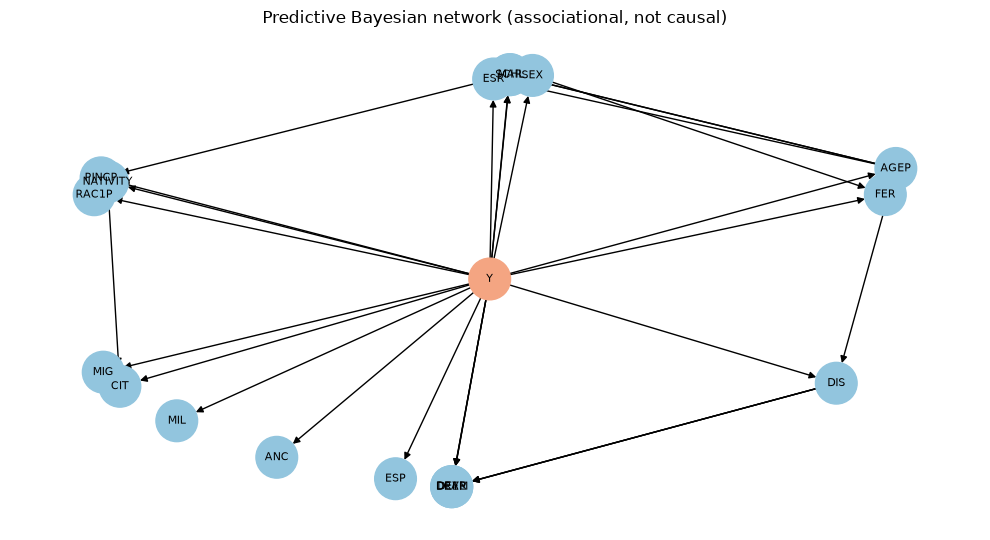

In [5]:
PARENTS = {"AGEP": ["Y"], "SCHL": ["Y", "AGEP"], "ESR": ["Y", "AGEP"], "PINCP": ["Y", "ESR"], "DIS": ["Y", "AGEP"],
           "MAR": ["Y", "AGEP"], "SEX": ["Y"], "RAC1P": ["Y"], "NATIVITY": ["Y"], "CIT": ["Y", "NATIVITY"],
           "MIG": ["Y"], "MIL": ["Y"], "ANC": ["Y"], "ESP": ["Y"], "DEAR": ["Y", "DIS"], "DEYE": ["Y", "DIS"],
           "DREM": ["Y", "DIS"], "FER": ["Y", "SEX"]}

class Factor:
    def __init__(self, vars_, card, values):
        self.vars, self.card, self.values = list(vars_), list(card), np.asarray(values, float)
        assert self.values.shape == tuple(self.card), "factor scope/shape mismatch"
    def _expand(self, v, cmap):
        order = sorted(self.vars, key=v.index)
        t = np.transpose(self.values, [self.vars.index(x) for x in order]) if self.vars else self.values
        return t.reshape([cmap[x] if x in self.vars else 1 for x in v])
    def product(self, o):
        v = self.vars + [x for x in o.vars if x not in self.vars]
        cmap = dict(zip(self.vars, self.card)); cmap.update(zip(o.vars, o.card))
        return Factor(v, [cmap[x] for x in v], self._expand(v, cmap) * o._expand(v, cmap))
    def marginalize(self, var):
        i = self.vars.index(var)
        return Factor(self.vars[:i] + self.vars[i+1:], self.card[:i] + self.card[i+1:], self.values.sum(i))
    def reduce(self, var, val):
        if var not in self.vars: return self
        i = self.vars.index(var)
        return Factor(self.vars[:i] + self.vars[i+1:], self.card[:i] + self.card[i+1:], np.take(self.values, val, i))

def variable_elimination(factors, query, evidence, order=None):
    fs = list(factors)
    for var, val in evidence.items(): fs = [f.reduce(var, val) for f in fs]
    hidden = {v for f in fs for v in f.vars} - {query}
    order = order or sorted(hidden, key=lambda h: sum(h in f.vars for f in fs))
    for h in order:
        inv = [f for f in fs if h in f.vars]; fs = [f for f in fs if h not in f.vars]
        if not inv: continue
        p = inv[0]
        for f in inv[1:]: p = p.product(f)
        fs.append(p.marginalize(h))
    p = fs[0]
    for f in fs[1:]: p = p.product(f)
    for v_ in [x for x in p.vars if x != query]: p = p.marginalize(v_)
    return p.values / p.values.sum()

class DiscreteBN:
    def __init__(self, parents=PARENTS, alpha=1.0): self.parents, self.alpha = dict(parents), alpha
    def fit(self, X, y):
        self.card = {c: int(X[c].max()) + 1 for c in self.parents}; self.card["Y"] = 2
        D = X.copy(); D["Y"] = y; self.cpt = {"Y": self._cpt(D, "Y", [])}
        for c, pa in self.parents.items(): self.cpt[c] = self._cpt(D, c, pa)
        return self
    def _cpt(self, D, c, pa):
        cnt = np.zeros([self.card[p] for p in pa] + [self.card[c]])
        np.add.at(cnt, tuple(np.clip(D[v].values, 0, self.card[v] - 1) for v in pa + [c]), 1.0)
        t = (cnt + self.alpha) / (cnt + self.alpha).sum(-1, keepdims=True)    # Dirichlet smoothing
        assert np.allclose(t.sum(-1), 1); return t
    def factors(self):
        return [Factor(["Y"], [2], self.cpt["Y"])] + [Factor(pa + [c], [self.card[v] for v in pa + [c]], self.cpt[c]) for c, pa in self.parents.items()]
    def predict_proba(self, X):     # full evidence: vectorised special case of VE
        n = len(X); lp = np.tile(np.log(self.cpt["Y"]), (n, 1))
        for yv in (0, 1):
            for c, pa in self.parents.items():
                idx = tuple(np.full(n, yv) if p == "Y" else np.clip(X[p].values, 0, self.card[p] - 1) for p in pa)
                lp[:, yv] += np.log(self.cpt[c][idx + (np.clip(X[c].values, 0, self.card[c] - 1),)])
        lp -= lp.max(1, keepdims=True); p = np.exp(lp); return p[:, 1] / p.sum(1)
    def query(self, ev, order=None): return variable_elimination(self.factors(), "Y", ev, order)

G_bn = nx.DiGraph([(p, c) for c, pa in PARENTS.items() for p in pa])
plt.figure(figsize=(10, 5.5)); pos = nx.kamada_kawai_layout(G_bn)
nx.draw_networkx(G_bn, pos, node_color=["#f4a582" if n == "Y" else "#92c5de" for n in G_bn], node_size=900, font_size=8, arrowsize=10)
plt.title("Predictive Bayesian network (associational, not causal)"); plt.axis("off"); plt.tight_layout(); plt.savefig("figures/bn_structure.png", dpi=160); plt.show()

### 3.1 Inference correctness (protocol 10)
On a tractable 6-node sub-network fitted to real training data: our VE under two elimination orders,
pgmpy VE, pgmpy **clique-tree** belief propagation and brute-force enumeration must agree to a stated tolerance
(1e-9) under 200 random evidence masks. We also verify CPT normalisation, that the vectorised predictor equals
general VE on the full network, and a **joint** conditional independence implied by d-separation.

In [6]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination, BeliefPropagation

tr0, va0, te0 = household_split(df, 0)
Xtr0, E0 = discretize(tr0); Xte0, _ = discretize(te0, E0)
SMALL = {"AGEP": ["Y"], "ESR": ["Y", "AGEP"], "PINCP": ["Y", "ESR"], "DIS": ["Y", "AGEP"], "SEX": ["Y"]}
bn_s = DiscreteBN(SMALL).fit(Xtr0, tr0.Y.values)

def enumerate_post(bn, ev):
    vs = ["Y"] + list(bn.parents); p = np.zeros(2)
    for a in itertools.product(*[range(bn.card[v]) for v in vs]):
        a = dict(zip(vs, a))
        if any(a[k] != v for k, v in ev.items()): continue
        pr = bn.cpt["Y"][a["Y"]]
        for c, pa in bn.parents.items(): pr *= bn.cpt[c][tuple(a[x] for x in pa) + (a[c],)]
        p[a["Y"]] += pr
    return p / p.sum()

m = DiscreteBayesianNetwork([(p, c) for c, pa in SMALL.items() for p in pa])
m.add_cpds(TabularCPD("Y", 2, bn_s.cpt["Y"].reshape(2, 1)))
for c, pa in SMALL.items():
    t = bn_s.cpt[c]; m.add_cpds(TabularCPD(c, bn_s.card[c], t.reshape(-1, t.shape[-1]).T, evidence=pa, evidence_card=[bn_s.card[p] for p in pa]))
assert m.check_model()
ve, bp = VariableElimination(m), BeliefPropagation(m); rng = np.random.default_rng(0); worst = 0
for _ in range(200):
    row = Xte0.iloc[rng.integers(len(Xte0))]; ev = {v: int(row[v]) for v in SMALL if rng.random() < .6}
    ref = enumerate_post(bn_s, ev)
    cands = [bn_s.query(ev), bn_s.query(ev, order=sorted(set(SMALL) - set(ev), reverse=True)),
             ve.query(["Y"], evidence=ev, show_progress=False).values, bp.query(["Y"], evidence=ev, show_progress=False).values]
    worst = max(worst, max(np.abs(c - ref).max() for c in cands))
print(f"max |posterior difference| (own VE x2 orders, pgmpy VE, clique tree, enumeration): {worst:.2e}"); assert worst < 1e-9
bn_full = DiscreteBN().fit(Xtr0, tr0.Y.values)
ev = {k: int(Xte0.iloc[3][k]) for k in PARENTS}
assert abs(bn_full.predict_proba(Xte0.iloc[[3]])[0] - bn_full.query(ev)[1]) < 1e-9; print("vectorised predictor == general VE on the full BN")
for yv in (0, 1):   # joint CI: SEX ⟂ {AGEP, DIS} | Y  (d-separated in SMALL); tested jointly, not pairwise
    J = ve.query(["SEX", "AGEP", "DIS"], evidence={"Y": yv}, joint=True, show_progress=False)
    P = np.array([[[J.get_value(SEX=s, AGEP=a, DIS=d) for d in range(bn_s.card["DIS"])] for a in range(bn_s.card["AGEP"])] for s in range(bn_s.card["SEX"])])
    assert np.allclose(P, P.sum((1, 2), keepdims=True) * P.sum(0, keepdims=True), atol=1e-12)
print("joint CI SEX ⟂ {AGEP, DIS} | Y verified in fitted model; positivity holds (Dirichlet smoothing => all CPT entries > 0)")

max |posterior difference| (own VE x2 orders, pgmpy VE, clique tree, enumeration): 3.33e-16
vectorised predictor == general VE on the full BN
joint CI SEX ⟂ {AGEP, DIS} | Y verified in fitted model; positivity holds (Dirichlet smoothing => all CPT entries > 0)


## 4. Predictive models and fairness metrics (shared notation)
Baselines: logistic regression and gradient-boosted trees on the same information and splits. **All three
models use RAC1P, SEX, DIS as features** (they are in the Folktables feature set), so all require protected
attributes at prediction time (protocol 3). Rules with λ > 0 in Section 10 additionally use group-specific thresholds.

In [7]:
LR_CAT = BN_CAT
def fit_all(tr, va, te, seed, which=("BN", "LR", "GBT")):
    Xtr, e = discretize(tr); Xva, _ = discretize(va, e); Xte, _ = discretize(te, e); out = {}
    if "BN" in which:
        bn = DiscreteBN().fit(Xtr, tr.Y.values); out["BN"] = (bn.predict_proba(Xva), bn.predict_proba(Xte))
    if "LR" in which:
        oh = OneHotEncoder(handle_unknown="ignore").fit(tr[LR_CAT].astype(int))
        M = lambda d: hstack([oh.transform(d[LR_CAT].astype(int)), csr_matrix(d[["AGEP", "SCHL", "PINCP"]].values / [65, 24, 3e4])]).tocsr()
        lr = LogisticRegression(max_iter=2000).fit(M(tr), tr.Y); out["LR"] = (lr.predict_proba(M(va))[:, 1], lr.predict_proba(M(te))[:, 1])
    if "GBT" in which:
        gb = HistGradientBoostingClassifier(random_state=seed, max_iter=300, learning_rate=.08).fit(tr[FEATURES], tr.Y)
        out["GBT"] = (gb.predict_proba(va[FEATURES])[:, 1], gb.predict_proba(te[FEATURES])[:, 1])
    return out

def topcap(s_fit, s_apply, cap=CAP):           # group-unaware rule: threshold fitted on validation
    return (s_apply >= np.quantile(s_fit, 1 - cap)).astype(int)

def group_table(y, d, g):
    t = pd.DataFrame(dict(y=y, d=d, g=g)); r = t.groupby("g").agg(n=("y", "size"), n_pos=("y", "sum"), sel=("d", "sum"))
    r["n_neg"] = r.n - r.n_pos
    r["k"] = t[t.y == 1].groupby("g").d.sum().reindex(r.index).fillna(0)
    r["fp"] = t[t.y == 0].groupby("g").d.sum().reindex(r.index).fillna(0)
    r["s_g"] = r.sel / r.n; r["t_g"] = r.k / r.n_pos.replace(0, np.nan); r["f_g"] = r.fp / r.n_neg.replace(0, np.nan)
    r["exploratory"] = (r.n_pos < MIN_SUPPORT) | (r.n_neg < MIN_SUPPORT)
    return r

def fairness_metrics(y, d, g, min_support=MIN_SUPPORT):
    r = group_table(y, d, g); A = r[r.n >= min_support]; P_ = r[r.n_pos >= min_support]; N_ = r[r.n_neg >= min_support]
    rng_ = lambda s: s.max() - s.min() if len(s) else np.nan
    dTPR, dFPR = rng_(P_.t_g), rng_(N_.f_g)
    return dict(groups=len(r), groups_adequate=len(P_), dDP=rng_(A.s_g), R_sel=(A.s_g.min() / A.s_g.max()) if A.s_g.max() > 0 else np.nan,
                dEOpp=dTPR, dEOdds=max(dTPR, dFPR), worst_recall=P_.t_g.min() if len(P_) else np.nan,
                dEOpp_all=rng_(r.t_g.dropna()), worst_recall_all=r.t_g.min())

def group_ece(y, p, g, min_n=200, bins=10):
    out = {}
    for gg in np.unique(g):
        mk = g == gg
        if mk.sum() < min_n: continue
        b = np.clip((p[mk] * bins).astype(int), 0, bins - 1)
        out[gg] = sum(abs(y[mk][b == i].mean() - p[mk][b == i].mean()) * (b == i).mean() for i in range(bins) if (b == i).any())
    return out

### 4.1 Predictive, probabilistic and fairness results for all models (5 household splits)

In [8]:
pred_rows, scores = [], {}
for s in SEEDS:
    tr, va, te = household_split(df, s); S = fit_all(tr, va, te, s); scores[s] = (tr, va, te, S)
    for mname, (sv, st) in S.items():
        d = topcap(sv, st); fm = fairness_metrics(te.Y.values, d, te.G.values); ece = group_ece(te.Y.values, st, te.G.values)
        pred_rows.append(dict(seed=s, model=mname, AUROC=roc_auc_score(te.Y, st), AP=average_precision_score(te.Y, st),
                              logloss=log_loss(te.Y, st), brier=brier_score_loss(te.Y, st), recall_at_cap=d[te.Y.values == 1].mean(),
                              precision_at_cap=te.Y.values[d == 1].mean(), max_group_ECE=max(ece.values()), **fm))
PRED = pd.DataFrame(pred_rows); PRED.to_csv("results/predictive_and_fairness_by_seed.csv", index=False)
print(PRED.drop(columns="seed").groupby("model").agg(["mean", "std"]).round(3).T.to_string())

model                      BN     GBT      LR
AUROC            mean   0.729   0.768   0.716
                 std    0.004   0.003   0.004
AP               mean   0.803   0.836   0.787
                 std    0.002   0.002   0.002
logloss          mean   0.577   0.541   0.584
                 std    0.004   0.003   0.002
brier            mean   0.196   0.182   0.199
                 std    0.002   0.001   0.001
recall_at_cap    mean   0.388   0.409   0.384
                 std    0.005   0.006   0.006
precision_at_cap mean   0.824   0.860   0.809
                 std    0.004   0.002   0.004
max_group_ECE    mean   0.110   0.063   0.069
                 std    0.010   0.013   0.011
groups           mean  33.400  33.400  33.400
                 std    1.517   1.517   1.517
groups_adequate  mean  22.200  22.200  22.200
                 std    1.095   1.095   1.095
dDP              mean   0.655   0.508   0.548
                 std    0.016   0.013   0.021
R_sel            mean   0.000   0.

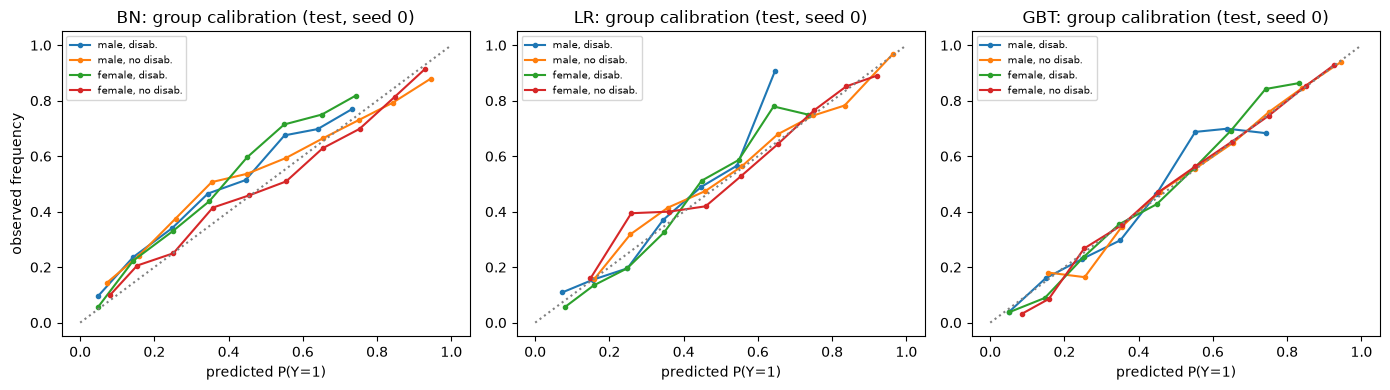

In [9]:
tr, va, te, S = scores[0]; fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (mname, (_, st)) in zip(ax, S.items()):
    for gg, lab in [("1|1", "male, disab."), ("1|2", "male, no disab."), ("2|1", "female, disab."), ("2|2", "female, no disab.")]:
        mk = (te.SEXc + "|" + te.DISc).values == gg; b = np.clip((st[mk] * 10).astype(int), 0, 9)
        xs = [st[mk][b == i].mean() for i in range(10) if (b == i).sum() >= 20]; ys = [te.Y.values[mk][b == i].mean() for i in range(10) if (b == i).sum() >= 20]
        a.plot(xs, ys, "o-", ms=3, label=lab)
    a.plot([0, 1], [0, 1], ":", c="gray"); a.set_title(f"{mname}: group calibration (test, seed 0)"); a.set_xlabel("predicted P(Y=1)"); a.legend(fontsize=7)
ax[0].set_ylabel("observed frequency"); plt.tight_layout(); plt.savefig("figures/group_calibration.png", dpi=160); plt.show()

## 5. Experiment 1 — single-attribute vs two-attribute vs intersectional audit
Unconstrained group-unaware top-30% rule, test split, all three models. Gaps use groups with ≥30 relevant
observations; `_all` versions include exploratory cells.

In [10]:
rows = []
for mname, (sv, st) in S.items():
    d = topcap(sv, st)
    for name, gcol in [("RACE", te.RACE), ("SEX", te.SEXc), ("DIS", te.DISc), ("RACE×SEX", te.RACE + "|" + te.SEXc),
                       ("SEX×DIS", te.SEXc + "|" + te.DISc), ("RACE×DIS", te.RACE + "|" + te.DISc), ("RACE×SEX×DIS", te.G)]:
        rows.append(dict(model=mname, grouping=name, **fairness_metrics(te.Y.values, d, gcol.values)))
EXP1 = pd.DataFrame(rows); EXP1.to_csv("results/exp1_single_two_three_way.csv", index=False)
print(EXP1.round(3).to_string(index=False))
d_bn = topcap(S["BN"][0], S["BN"][1]); GT = group_table(te.Y.values, d_bn, te.G.values); GT["race"] = [RACE_NAMES[g.split("|")[0]] for g in GT.index]
print("\nIntersectional denominators and rates (BN, seed 0, test):"); print(GT.sort_values("n_pos").round(3).to_string())

model     grouping  groups  groups_adequate   dDP  R_sel  dEOpp  dEOdds  worst_recall  dEOpp_all  worst_recall_all
   BN         RACE       9                8 0.548  0.073  0.597   0.597         0.079      0.675             0.000
   BN          SEX       2                2 0.128  0.633  0.162   0.162         0.291      0.162             0.291
   BN          DIS       2                2 0.324  0.021  0.384   0.384         0.021      0.384             0.021
   BN     RACE×SEX      18               14 0.614  0.041  0.678   0.678         0.059      0.737             0.000
   BN      SEX×DIS       4                4 0.386  0.008  0.468   0.468         0.009      0.468             0.009
   BN     RACE×DIS      18               13 0.634  0.000  0.697   0.697         0.000      0.697             0.000
   BN RACE×SEX×DIS      35               21 0.683  0.000  0.746   0.746         0.000      0.746             0.000
   LR         RACE       9                8 0.456  0.117  0.561   0.561         

## 6. Hierarchical Bayesian audit models
For each intersection g with n_g positives, k_g of which are selected:  k_g | θ_g ~ Binomial(n_g, θ_g), θ_g = TPR.

| Estimator | Prior on θ_g | Role |
|---|---|---|
| raw | none (k/n) | fairness baseline: empirical subgroup audit |
| independent | Beta(1,1) per group | ablation: **no pooling** |
| complete | one shared θ | ablation: **complete pooling** |
| hier (EB) | Beta(a,b), (a,b) by marginal likelihood | ordinary partial pooling |
| fullbayes | Beta(μκ,(1−μ)κ), μ~U(0,1), p(κ)∝(1+κ)⁻² (grid posterior) | fully-Bayesian exchangeable hierarchical audit (BDA-style; NOT an exact reproduction of [24]) |
| **struct** | logit θ_g = β0 + β_race[r] + β_sex[s] + β_dis[d] + u_g, u_g ~ N(0, τ²) | **established-hierarchical baseline**: attribute-structured hierarchical logistic audit (below) |
| **robust (proposed)** | π·Beta(a,b) + (1−π)·Beta(1,1), π ≤ π_max | ε-contamination prior: atypical groups escape shrinkage |

**Attribute-structured audit (`struct`).** `hier` and `fullbayes` are *exchangeable*: they shrink every intersection toward
one grand mean. Intersectional hierarchical models instead share strength **through the attributes**: a group's estimate is
pulled toward the prediction from its race, sex and disability main effects, and u_g is the group-specific interaction.
β (treatment-coded; reference level = most common level of each attribute) and log τ are fitted by **marginal likelihood**
(empirical Bayes), integrating each u_g by adaptive quadrature: 201 equally spaced nodes centred at the conditional mode of
u_g and spanning ±12 Laplace standard deviations. (A fixed ±6τ grid is too coarse for groups with thousands of positives,
whose likelihood in u_g is ≈0.01 wide.) The gradient is exact: posterior expectations of the score. Posterior draws of u_g
come from its grid posterior with uniform jitter inside the cell. Bounds |β| ≤ 20, τ ∈ [0.01, 10] keep the fit finite when
every group at a level has k = 0. Like `hier`, it plugs in the fitted (β, τ), so hyperparameter uncertainty is not propagated.
*This is a documented restricted version of a hierarchical intersectional audit in the spirit of [24]. Exact reproduction is
pending the literature step.* It is **not** claimed to be Foulds et al.'s model.

Decision rules for "tolerance satisfied (ΔEOpp ≤ ε)": **plugin** = max−min of posterior means ≤ ε;
**upper** = q-quantile of the posterior of max_g θ_g − min_g θ_g ≤ ε, equivalently P(ΔEOpp > ε | data) ≤ 1 − q.

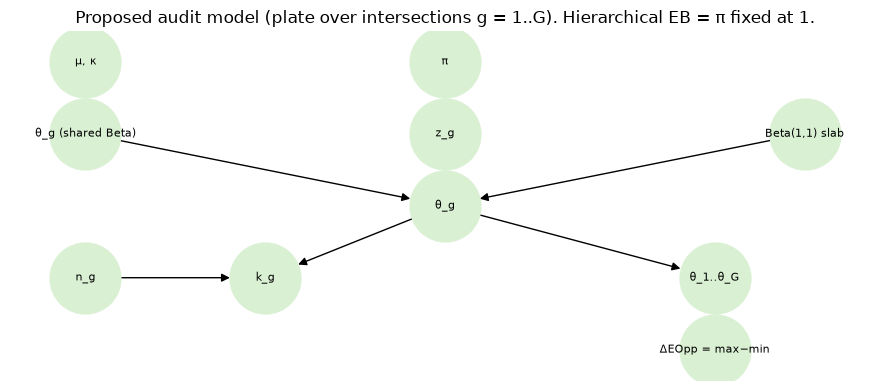

In [11]:
LOGK_MIN, LOGK_MAX = np.log(.5), np.log(1e4)    # pooling-strength bounds, shared by EB, full-Bayes grid and proposed prior
def bb_logpmf(k, n, a, b):
    return gammaln(n + 1) - gammaln(k + 1) - gammaln(n - k + 1) + betaln(k + a, n - k + b) - betaln(a, b)

def fit_eb(k, n):
    def nll(p):
        mu, kap = 1 / (1 + np.exp(-p[0])), np.exp(np.clip(p[1], LOGK_MIN, LOGK_MAX)); return -bb_logpmf(k, n, mu * kap, (1 - mu) * kap).sum()
    m0 = np.clip(k.sum() / max(n.sum(), 1), .01, .99)
    r = minimize(nll, [np.log(m0 / (1 - m0)), np.log(20)], method="Nelder-Mead")
    mu, kap = 1 / (1 + np.exp(-r.x[0])), np.exp(np.clip(r.x[1], LOGK_MIN, LOGK_MAX)); return mu * kap, (1 - mu) * kap

def fit_robust(k, n, pi_max=.95, slab=(1, 1), slab_c=None):
    """slab_c=None: fixed slab Beta(slab) (v1). slab_c=c: slab Beta(mu*c, (1-mu)*c) centred on the shared mean (v2, §17)."""
    def comps(p):
        mu, kap, pi = 1 / (1 + np.exp(-p[0])), np.exp(np.clip(p[1], LOGK_MIN, LOGK_MAX)), pi_max / (1 + np.exp(-p[2]))
        sl = (mu * slab_c, (1 - mu) * slab_c) if slab_c else slab
        return np.log(pi) + bb_logpmf(k, n, mu * kap, (1 - mu) * kap), np.log(1 - pi) + bb_logpmf(k, n, *sl), mu, kap, pi, sl
    nll = lambda p: -np.logaddexp(*comps(p)[:2]).sum()
    m0 = np.clip(k.sum() / max(n.sum(), 1), .01, .99)
    best = min((minimize(nll, [np.log(m0 / (1 - m0)), np.log(k0), 2.], method="Nelder-Mead") for k0 in (5, 50, 500)), key=lambda r: r.fun)
    l1, l0, mu, kap, pi, sl = comps(best.x)      # same bounded kappa for fit, weights and sampling
    return mu * kap, (1 - mu) * kap, pi, np.exp(l1 - np.logaddexp(l1, l0)), sl

BETA_MAX, LOGT_MIN, LOGT_MAX, Z_NODES = 20., np.log(.01), np.log(10.), np.linspace(-12, 12, 201)
def struct_design(labels):
    """Treatment-coded main effects of race, sex, disability parsed from labels 'race|sex|dis'.
    Reference level of each attribute = the level with the most groups (ties: lowest code)."""
    parts = np.array([str(l).split("|") for l in labels]); cols, names = [np.ones(len(parts))], ["intercept"]
    for j, att in enumerate(["race", "sex", "dis"]):
        lev, cnt = np.unique(parts[:, j], return_counts=True); ref = lev[np.argmax(cnt)]
        for l in lev:
            if l != ref: cols.append((parts[:, j] == l).astype(float)); names.append(f"{att}={l}")
    return np.column_stack(cols), names

def struct_grid(k, n, eta, tau):
    """Conditional posterior of u_g on a 201-node grid centred at its mode (Newton) and spanning ±12 Laplace sds.
    Returns nodes, log un-normalised density (binomial kernel x N(0,tau^2)), spacing. Exact up to quadrature error."""
    u = np.zeros_like(eta)
    for _ in range(200):
        p = expit(eta + u); step = np.clip((k - n * p - u / tau**2) / (n * p * (1 - p) + 1 / tau**2), -2, 2); u = u + step
        if np.abs(step).max() < 1e-10: break
    p = expit(eta + u); s = 1 / np.sqrt(n * p * (1 - p) + 1 / tau**2)
    U = u[:, None] + s[:, None] * Z_NODES[None]; eU = eta[:, None] + U
    lf = k[:, None] * -np.logaddexp(0, -eU) + (n - k)[:, None] * -np.logaddexp(0, eU) - .5 * (U / tau)**2
    return U, lf, s * (Z_NODES[1] - Z_NODES[0])

def struct_negloglik(par, k, n, X):
    """Marginal likelihood of (beta, log tau): prod_g int Bin(k_g | n_g, expit(x_g beta + u)) N(u; 0, tau^2) du, and its
    exact gradient (posterior expectations of the score under the quadrature posterior)."""
    beta, tau = par[:-1], np.exp(par[-1]); eta = X @ beta
    U, lf, du = struct_grid(k, n, eta, tau); m = lf.max(1, keepdims=True); w = np.exp(lf - m); Z = w.sum(1, keepdims=True); w /= Z
    ll = (np.log(Z[:, 0]) + m[:, 0] + np.log(du) - np.log(tau * np.sqrt(2 * np.pi)) + gammaln(n + 1) - gammaln(k + 1) - gammaln(n - k + 1)).sum()
    g_eta = (w * (k[:, None] - n[:, None] * expit(eta[:, None] + U))).sum(1); g_lt = (w * ((U / tau)**2 - 1)).sum(1).sum()
    return -ll, -np.append(X.T @ g_eta, g_lt)

def fit_struct(k, n, labels):
    X, names = struct_design(labels); m0 = np.clip(k.sum() / max(n.sum(), 1), .01, .99)
    bounds = [(-BETA_MAX, BETA_MAX)] * X.shape[1] + [(LOGT_MIN, LOGT_MAX)]
    best = min((minimize(struct_negloglik, np.r_[np.log(m0 / (1 - m0)), np.zeros(X.shape[1] - 1), np.log(t0)], args=(k, n, X),
                         jac=True, method="L-BFGS-B", bounds=bounds) for t0 in (.1, 1.)), key=lambda r: r.fun)
    return best.x[:-1], float(np.exp(best.x[-1])), X, names, -best.fun

def struct_draws(k, n, eta, tau, S, rng):
    """S posterior draws of theta_g = expit(eta_g + u_g) given (eta, tau): grid draw, then uniform jitter inside the cell."""
    U, lf, du = struct_grid(k, n, eta, tau); w = np.exp(lf - lf.max(1, keepdims=True)); w /= w.sum(1, keepdims=True); G = len(k)
    idx = np.array([rng.choice(len(Z_NODES), S, p=w[g]) for g in range(G)]).T
    return expit(eta[None] + U[np.arange(G)[None], idx] + du[None] * (rng.random((S, G)) - .5))

SLAB_C = 2.0                                     # v2 (§17): prior sample size of the centred slab
MU_G, LK_G = np.linspace(.005, .995, 60), np.linspace(LOGK_MIN, LOGK_MAX, 60)
def posterior(k, n, method, S=4000, rng=None, pi_max=.95, slab=(1, 1), labels=None):
    rng = rng or np.random.default_rng(0); k = np.asarray(k, float); n = np.asarray(n, float); G = len(k); info = {}
    if method == "independent": return rng.beta(1 + k, 1 + n - k, (S, G)), info
    if method == "complete":
        return np.tile(rng.beta(1 + k.sum(), 1 + (n - k).sum(), S)[:, None], (1, G)), info
    if method == "hier":
        a, b = fit_eb(k, n); info.update(a=a, b=b); return rng.beta(a + k, b + n - k, (S, G)), info
    if method == "fullbayes":
        MU, LK = np.meshgrid(MU_G, LK_G); MU, KAP = MU.ravel(), np.exp(LK.ravel())
        lp = bb_logpmf(k[None], n[None], (MU * KAP)[:, None], ((1 - MU) * KAP)[:, None]).sum(1) - 2 * np.log1p(KAP) + np.log(KAP)
        w = np.exp(lp - lp.max()); w /= w.sum(); i = rng.choice(len(w), S, p=w); a, b = (MU * KAP)[i, None], ((1 - MU) * KAP)[i, None]
        info.update(kappa_post_mean=float((KAP * w).sum())); return rng.beta(a + k, b + n - k), info
    if method in ("robust", "robustc"):
        a, b, pi, w, sl = fit_robust(k, n, pi_max, slab, slab_c=SLAB_C if method == "robustc" else None)
        info.update(a=a, b=b, pi=pi, w_pooled=w, slab_fit=sl)
        z = rng.random((S, G)) < w
        return np.where(z, rng.beta(a + k, b + n - k, (S, G)), rng.beta(sl[0] + k, sl[1] + n - k, (S, G))), info
    if method == "struct":
        assert labels is not None and len(labels) == G, "struct needs one 'race|sex|dis' label per group"
        beta, tau, X, names, ll = fit_struct(k, n, labels); eta = X @ beta
        info.update(beta=dict(zip(names, beta)), tau=tau, loglik=ll, prior_mean=expit(eta)); return struct_draws(k, n, eta, tau, S, rng), info
    raise ValueError(method)

def audit(k, n, method, eps=EPS, qs=(Q_DEFAULT,), S=4000, rng=None, labels=None, **kw):
    k = np.asarray(k, float); n = np.asarray(n, float); keep = n >= 1; k, n = k[keep], n[keep]   # n=0 groups reported separately
    if labels is not None: kw["labels"] = np.asarray(labels)[keep]                               # same keep mask as k, n
    if method == "raw":
        t = k / n; return dict(keep=keep, means=t, plugin_gap=t.max() - t.min())
    th, info = posterior(k, n, method, S, rng, **kw); gaps = th.max(1) - th.min(1); means = th.mean(0)
    out = dict(keep=keep, means=means, plugin_gap=means.max() - means.min(), p_exceed=(gaps > eps).mean(),
               ci90=tuple(np.quantile(gaps, [.05, .95])), samples=th, gaps=gaps, **info)
    for q in qs: out[f"upper_{q}"] = np.quantile(gaps, q)
    return out

def ppc(k, n, th, rng, min_n=MIN_SUPPORT):
    """Posterior predictive check: T = range of empirical TPR over adequately supported groups."""
    k = np.asarray(k, float); n = np.asarray(n, float); m = n >= min_n
    T = lambda kk: (kk[..., m] / n[m]).max(-1) - (kk[..., m] / n[m]).min(-1)
    rep = rng.binomial(n.astype(int)[None], th[:500]); return float((T(rep) >= T(k)).mean())

# hierarchical dependency structure (interpretability requirement)
H = nx.DiGraph([("μ, κ", "θ_g (shared Beta)"), ("π", "z_g"), ("z_g", "θ_g"), ("θ_g (shared Beta)", "θ_g"), ("Beta(1,1) slab", "θ_g"),
                ("θ_g", "k_g"), ("n_g", "k_g"), ("θ_1..θ_G", "ΔEOpp = max−min"), ("θ_g", "θ_1..θ_G")])
plt.figure(figsize=(9, 4)); pos = {"μ, κ": (0, 2), "π": (2, 2), "θ_g (shared Beta)": (0, 1), "z_g": (2, 1), "Beta(1,1) slab": (4, 1),
      "θ_g": (2, 0), "k_g": (1, -1), "n_g": (0, -1), "θ_1..θ_G": (3.5, -1), "ΔEOpp = max−min": (3.5, -2)}
nx.draw_networkx(H, pos, node_color="#d9f0d3", node_size=2600, font_size=8, arrowsize=12)
plt.title("Proposed audit model (plate over intersections g = 1..G). Hierarchical EB = π fixed at 1."); plt.axis("off"); plt.tight_layout()
plt.savefig("figures/audit_model_structure.png", dpi=160); plt.show()

### 6.1 Checks of the attribute-structured audit (`struct`)
The design for these checks is the real **seed-0 validation split**: its 32 non-empty intersections and their positive
counts (validation data only; no test data). (a) Quadrature: the marginal log-likelihood from the adaptive 201-node grid
is compared with brute-force integration on a fixed grid with spacing 2·10⁻⁴. (b) The analytic gradient is compared with
central finite differences. (c) Frequentist coverage: R = 200 datasets generated **exactly from the struct model** (main
effects plus N(0, τ²) interactions, no outlier); we report how often the central 90% posterior interval of each θ_g
covers the true θ_g. The number is reported as it comes out; nothing is tuned to hit 0.90. This is **SYNTHETIC** data on a
real design.

In [12]:
VAL_POS = va0[va0.Y == 1].groupby("G").size()                    # seed-0 validation positives per intersection
VAL_LAB, VAL_N = VAL_POS.index.values, VAL_POS.values.astype(float)
print(f"validation design: {len(VAL_N)} non-empty intersections, positives {int(VAL_N.min())}..{int(VAL_N.max())}, 2|2|1 has {int(VAL_POS['2|2|1'])}")
Xd, xnames = struct_design(VAL_LAB); rs = np.random.default_rng(11)
BETA_TRUE = np.r_[np.log(.38 / .62), rs.normal(0, .3, Xd.shape[1] - 1)]; TAU_TRUE = .3
# (a) quadrature accuracy and (b) gradient check, at the true parameters and at a strongly pooled / weakly pooled point
worst_q = worst_g = 0
for tau_c in (.05, TAU_TRUE, 2.):
    th_c = expit(Xd @ BETA_TRUE + rs.normal(0, tau_c, len(VAL_N))); kc = rs.binomial(VAL_N.astype(int), th_c).astype(float)
    par = np.r_[BETA_TRUE, np.log(tau_c)]; f_ad, g_ad = struct_negloglik(par, kc, VAL_N, Xd)
    uu = np.arange(-12 * tau_c - 1, 12 * tau_c + 1, 2e-4); eu = (Xd @ BETA_TRUE)[:, None] + uu[None]
    lf = kc[:, None] * -np.logaddexp(0, -eu) + (VAL_N - kc)[:, None] * -np.logaddexp(0, eu) - .5 * (uu / tau_c)**2
    mx = lf.max(1); ll_bf = (np.log(np.exp(lf - mx[:, None]).sum(1) * 2e-4) + mx - np.log(tau_c * np.sqrt(2 * np.pi))
                             + gammaln(VAL_N + 1) - gammaln(kc + 1) - gammaln(VAL_N - kc + 1)).sum()
    fd = np.array([(struct_negloglik(par + h, kc, VAL_N, Xd)[0] - struct_negloglik(par - h, kc, VAL_N, Xd)[0]) / 2e-6 for h in np.eye(len(par)) * 1e-6])
    worst_q, worst_g = max(worst_q, abs(-f_ad - ll_bf)), max(worst_g, np.abs(fd - g_ad).max())
print(f"(a) |adaptive quadrature − brute force| marginal log-lik: {worst_q:.2e}   (b) max |analytic − finite-difference gradient|: {worst_g:.2e}")
assert worst_q < 1e-6 and worst_g < 1e-3
# (c) coverage on data generated exactly from the model
t1 = time.time(); cov_rows = []
for r in range(200):
    th = expit(Xd @ BETA_TRUE + rs.normal(0, TAU_TRUE, len(VAL_N))); kk = rs.binomial(VAL_N.astype(int), th)
    a = audit(kk, VAL_N, "struct", qs=(.9,), S=2000, rng=rs, labels=VAL_LAB); lo, hi = np.quantile(a["samples"], [.05, .95], axis=0)
    glo, ghi = a["ci90"]; tg = th.max() - th.min()
    olo, ohi = np.quantile(struct_draws(kk.astype(float), VAL_N, Xd @ BETA_TRUE, TAU_TRUE, 2000, rs), [.05, .95], axis=0)  # oracle (β, τ)
    cov_rows += [dict(rep=r, g=g, n=VAL_N[i], covered=lo[i] <= th[i] <= hi[i], width=hi[i] - lo[i], tau_hat=a["tau"],
                      oracle_covered=olo[i] <= th[i] <= ohi[i], gap_covered=glo <= tg <= ghi) for i, g in enumerate(VAL_LAB)]
COV = pd.DataFrame(cov_rows); COV["size band"] = pd.cut(COV.n, [0, 29, 299, 1e9], labels=["<30 positives", "30–299", "≥300"])
se_rep = lambda col: COV.groupby("rep")[col].mean().std() / np.sqrt(COV.rep.nunique())     # replicate-clustered MC s.e.
print(f"(c) {COV.rep.nunique()} replicates, {time.time()-t1:.0f}s.  Overall 90% coverage of θ_g (EB plug-in): {COV.covered.mean():.3f} "
      f"± {se_rep('covered'):.3f} (MC s.e., clustered by replicate)")
print(COV.groupby("size band", observed=True).agg(groups=("g", "nunique"), coverage90_EB=("covered", "mean"), coverage90_oracle=("oracle_covered", "mean"),
                                                  mean_width_EB=("width", "mean")).round(3).to_string())
print(f"Oracle check (same sampler at the true β, τ; must be ≈0.90 if the implementation is right): {COV.oracle_covered.mean():.3f} ± {se_rep('oracle_covered'):.3f}")
print(f"τ̂: mean {COV.groupby('rep').tau_hat.first().mean():.3f} (true {TAU_TRUE}); share of fits at the lower bound τ=0.01: "
      f"{(COV.groupby('rep').tau_hat.first() < .0101).mean():.2f}.  Coverage of the 90% interval for the max−min gap: {COV.groupby('rep').gap_covered.first().mean():.3f}")
COV.to_csv("results/struct_coverage_check.csv", index=False)

validation design: 32 non-empty intersections, positives 1..5499, 2|2|1 has 24


(a) |adaptive quadrature − brute force| marginal log-lik: 9.56e-11   (b) max |analytic − finite-difference gradient|: 2.01e-06


(c) 200 replicates, 11s.  Overall 90% coverage of θ_g (EB plug-in): 0.665 ± 0.014 (MC s.e., clustered by replicate)
               groups  coverage90_EB  coverage90_oracle  mean_width_EB
size band                                                             
<30 positives      10          0.532              0.914          0.135
30–299             11          0.642              0.903          0.110
≥300               11          0.810              0.899          0.049
Oracle check (same sampler at the true β, τ; must be ≈0.90 if the implementation is right): 0.905 ± 0.004
τ̂: mean 0.184 (true 0.3); share of fits at the lower bound τ=0.01: 0.05.  Coverage of the 90% interval for the max−min gap: 0.600


**Findings, §6.1.** The quadrature matches brute-force integration to 1·10⁻¹⁰ and the analytic gradient matches finite
differences to 2·10⁻⁶. With the true (β, τ) plugged in, the sampler's 90% intervals cover 0.905 ± 0.004, so the
implementation is correct. With (β, τ) **estimated** by marginal likelihood, exactly as the audit is used, coverage is
only **0.665 ± 0.014**: 0.53 for groups with < 30 positives, 0.64 for 30–299 and 0.81 for ≥ 300. τ̂ averages 0.18 against a
true 0.30. This is the known downward bias of ML variance estimates with 11 fixed effects and 32 groups, and the plug-in
also ignores the uncertainty in β̂. **Even when its model is exactly right, the empirical-Bayes attribute-structured audit
gives over-confident intervals on this design.** The 90% interval for the max−min gap covers 0.60.

## 7. Experiment 3 — empirical vs independently smoothed vs pooled estimates (real data)

In [13]:
c = GT[GT.n_pos >= 1]; rng = np.random.default_rng(0); REAL_AUD = {}
tab = GT[["race", "n", "n_pos", "k", "t_g", "exploratory"]].copy()
for meth in ["independent", "hier", "fullbayes", "struct", "robust", "complete"]:
    a = audit(GT.k.values, GT.n_pos.values, meth, rng=rng, labels=GT.index.values); REAL_AUD[meth] = a
    tab[meth] = np.nan; tab.loc[tab.index[a["keep"]], meth] = a["means"]
tab["robust_w_pooled"] = np.nan; tab.loc[tab.index[REAL_AUD["robust"]["keep"]], "robust_w_pooled"] = REAL_AUD["robust"]["w_pooled"]
tab["struct_prior"] = np.nan; tab.loc[tab.index[REAL_AUD["struct"]["keep"]], "struct_prior"] = REAL_AUD["struct"]["prior_mean"]
tab["pull_hier"] = tab.hier - tab.t_g; tab["pull_struct"] = tab.struct - tab.t_g; tab["pull_robust"] = tab.robust - tab.t_g
print("struct fit on test counts: τ̂ =", round(REAL_AUD["struct"]["tau"], 3), " β̂ =", {k_: round(v, 2) for k_, v in REAL_AUD["struct"]["beta"].items()})
print("(struct_prior = expit(x_g β̂), the main-effects prediction each group is pulled toward; |β| = 20 means the bound is active)")
tab.sort_values("n_pos").round(3).to_csv("results/exp3_estimates_real.csv"); print(tab.sort_values("n_pos").round(3).to_string())
summ = []
for meth, a in REAL_AUD.items():
    summ.append(dict(estimator=meth, plugin_gap=a["plugin_gap"], upper90=a.get("upper_0.9"), ci90=a.get("ci90"),
                     p_exceed=a.get("p_exceed"), ppc_p=ppc(GT.k.values[a["keep"]], GT.n_pos.values[a["keep"]], a["samples"], rng) if "samples" in a else None))
print(pd.DataFrame(summ).round(3).to_string(index=False))
print("PPC p-values near 0 or 1 indicate the pooling model cannot reproduce the observed spread across well-supported groups.")

struct fit on test counts: τ̂ = 0.01  β̂ = {'intercept': np.float64(-4.37), 'race=2': np.float64(-1.99), 'race=3': np.float64(-1.56), 'race=4': np.float64(-14.72), 'race=5': np.float64(-1.44), 'race=6': np.float64(1.18), 'race=7': np.float64(0.98), 'race=8': np.float64(-1.63), 'race=9': np.float64(0.2), 'sex=2': np.float64(0.7), 'dis=2': np.float64(3.61)}
(struct_prior = expit(x_g β̂), the main-effects prediction each group is pulled toward; |β| = 20 means the bound is active)
             race     n  n_pos       k    t_g  exploratory  independent   hier  fullbayes  struct  robust  complete  robust_w_pooled  struct_prior  pull_hier  pull_struct  pull_robust
g                                                                                                                                                                                      
7|2|1        NHPI     4      0     0.0    NaN         True          NaN    NaN        NaN     NaN     NaN       NaN              NaN           NaN    

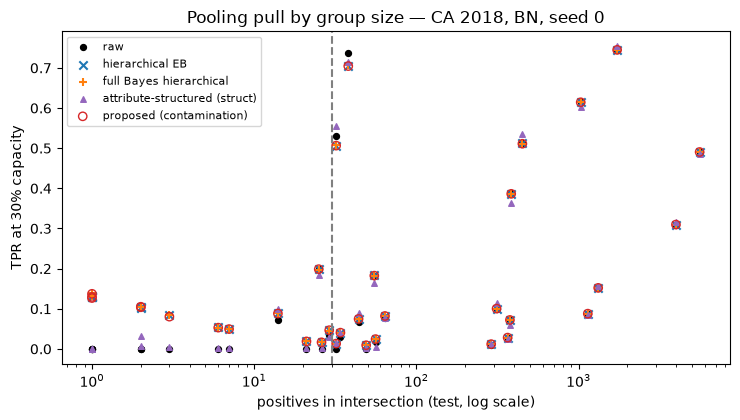

In [14]:
t = tab.dropna(subset=["t_g"]); fig, a = plt.subplots(figsize=(7.5, 4.3)); a.set_xscale("log")
a.scatter(t.n_pos, t.t_g, c="k", s=18, label="raw"); a.scatter(t.n_pos, t.hier, c="C0", marker="x", label="hierarchical EB")
a.scatter(t.n_pos, t.fullbayes, c="C1", marker="+", label="full Bayes hierarchical"); a.scatter(t.n_pos, t.struct, c="C4", marker="^", s=16, label="attribute-structured (struct)")
a.scatter(t.n_pos, t.robust, facecolors="none", edgecolors="C3", label="proposed (contamination)")
a.axvline(MIN_SUPPORT, ls="--", c="gray"); a.set_xlabel("positives in intersection (test, log scale)"); a.set_ylabel("TPR at 30% capacity")
a.set_title("Pooling pull by group size — CA 2018, BN, seed 0"); a.legend(fontsize=8); plt.tight_layout(); plt.savefig("figures/real_pooling_pull.png", dpi=160); plt.show()

**Findings, §7 (real data, seed 0, test).** The exchangeable estimators (hier, fullbayes, robust) move estimates
appreciably only for groups with 1–7 positives (pull 0.05–0.14). Every group with ≥ 30 positives moves by ≤ 0.032. The TPRs
are bimodal (DIS = 1 near 0; DIS = 2 mostly 0.07–0.75), so the fitted shared Beta is diffuse and the masking mechanism
of §8 is absent. `struct` fits **τ̂ = 0.01, the lower bound**, so on these counts it collapses to a pure main-effects
logistic model. It then pulls every small group to its main-effects prediction: the three Alaska-Native groups (3 positives
in total) go to TPR ≈ 0 instead of hier's ≈ 0.13. Its 90% interval for ΔEOpp is (0.750, 0.757), far narrower than hier's
(0.729, 0.816). PPC p-values are 0.64–0.85 for the independent and partial-pooling estimators, so none is rejected by the
spread of the well-supported groups. Complete pooling is rejected (p = 0.000). Every model gives P(ΔEOpp > 0.10 | data) = 1.0 for the unconstrained rule. The real disparity is far too large
for pooling to hide.

## 8. Sparse-group benchmark generator and known-truth simulation (Experiment 4) — **SYNTHETIC**
16 intersections with sizes 4000 → 8 positives. *Homogeneous*: true TPRs within ±0.015 of a base rate (true gap ≈ 0.03 < ε).
*Exceptional*: one 20-positive group sits δ = 0.20 below the base (true gap ≈ 0.21 > ε), optionally thinned.
Metrics: **FTS** = false tolerance-satisfaction rate (declared fair | truly unfair, lower is better);
**ACC** = correct acceptance (declared fair | truly fair); coverage and width of the central 90% interval for the gap;
probability the exceptional group is ranked worst. Simulated values are not facts about the real population.
The **semi-synthetic** counterpart on the real CA intersection design is §9.2. It comes after §9 because it evaluates the
procedure that §9 freezes.

In [15]:
SIZES = np.array([4000, 3000, 1500, 900, 600, 400, 300, 200, 120, 80, 60, 40, 30, 20, 12, 8])
def one_world(rng, scenario, keep=1.0, base=.65, spread=.03, delta=.20, sizes=SIZES):
    G = len(sizes); t = base + rng.uniform(-spread / 2, spread / 2, G); n = sizes.astype(float).copy(); ex = G - 3
    if scenario == "exceptional": t[ex] = base - delta; n[ex] = max(2, round(n[ex] * keep))
    n = rng.poisson(n).clip(1); return rng.binomial(n.astype(int), t), n, t, ex

ESTIMATORS = {"raw": {}, "independent": {}, "complete": {}, "hier": {}, "fullbayes": {},
              **{f"robust@{p}": dict(pi_max=p) for p in (.8, .9, .95, .99)}}
QS = (.5, .75, .9)
def simulate(R, scenarios, estimators=ESTIMATORS, eps_list=(EPS,), seed=0, **world_kw):
    rng = np.random.default_rng(seed); rows = []
    for scen, keep in scenarios:
        for r in range(R):
            k, n, t, ex = one_world(rng, scen, keep, **world_kw); tg = t.max() - t.min()
            for name, kw in estimators.items():
                a = audit(k, n, name.split("@")[0], qs=QS, S=2000, rng=rng, **kw)
                for eps in eps_list:
                    base = dict(scenario=scen, keep=keep, estimator=name, eps=eps, rep=r, true_gap=tg, truly_unfair=tg > eps,
                                ex_worst=float(np.argmin(a["means"]) == ex) if scen == "exceptional" else np.nan)
                    rows.append(dict(base, rule="plugin", declared_fair=a["plugin_gap"] <= eps))
                    if name != "raw":
                        lo, hi = a["ci90"]; cov, wid = float(lo <= tg <= hi), hi - lo
                        for q in QS: rows.append(dict(base, rule=f"upper{q}", declared_fair=a[f"upper_{q}"] <= eps, covered=cov, width=wid))
    return pd.DataFrame(rows)

def summarise(sim):
    g = sim.groupby(["scenario", "keep", "estimator", "rule", "eps"]).agg(declared_fair=("declared_fair", "mean"), coverage90=("covered", "mean"),
          width90=("width", "mean"), ex_worst=("ex_worst", "mean"), reps=("rep", "count")).reset_index()
    return g

t1 = time.time()
SIM = simulate(R_SIM, [("homogeneous", 1.0), ("exceptional", 1.0), ("exceptional", .5), ("exceptional", .25)])
SIMS = summarise(SIM); SIMS.to_csv("results/sim_main_summary.csv", index=False); print(f"main simulation: {time.time()-t1:.0f}s")
piv = SIMS.pivot_table(index=["estimator", "rule"], columns=["scenario", "keep"], values="declared_fair")
piv.columns = ["FTS keep=" + str(k) if s == "exceptional" else "ACC (homog.)" for s, k in piv.columns]
print(piv.round(3).to_string())
print(SIMS[SIMS.scenario == "exceptional"].groupby(["estimator"])[["coverage90", "width90", "ex_worst"]].mean().round(3).to_string())

main simulation: 153s
                       FTS keep=0.25  FTS keep=0.5  FTS keep=1.0  ACC (homog.)
estimator   rule                                                              
complete    plugin             1.000         1.000         1.000         1.000
            upper0.5           1.000         1.000         1.000         1.000
            upper0.75          1.000         1.000         1.000         1.000
            upper0.9           1.000         1.000         1.000         1.000
fullbayes   plugin             0.993         1.000         0.983         1.000
            upper0.5           0.967         0.970         0.937         0.960
            upper0.75          0.817         0.740         0.750         0.827
            upper0.9           0.397         0.337         0.310         0.427
hier        plugin             1.000         1.000         1.000         1.000
            upper0.5           1.000         1.000         0.993         0.993
            upper0.75         

## 9. Simulation calibration of the tolerance procedure (preregistered rule)
Problem 8 requires any claimed tolerance procedure to be calibrated by simulation. **Preregistered choice rule:**
among (estimator, rule) pairs, maximise Youden's J = ACC − FTS at keep = 1, breaking ties by lower FTS.
The chosen procedure is then fixed for all real-data selection. No real data are used here.

In [16]:
cal = piv.copy(); cal["J"] = cal["ACC (homog.)"] - cal["FTS keep=1.0"]
cal = cal.sort_values(["J", "FTS keep=1.0"], ascending=[False, True]); print(cal.round(3).head(10).to_string())
best_est, best_rule = cal.index[0]
PROPOSED = dict(name=best_est, pi_max=float(best_est.split("@")[1]) if "@" in best_est else None, q=float(best_rule.replace("upper", "")) if best_rule.startswith("upper") else None, rule=best_rule)
print("\nCALIBRATED PROCEDURE:", PROPOSED)
CAL_FTS, CAL_ACC = cal.iloc[0]["FTS keep=1.0"], cal.iloc[0]["ACC (homog.)"]
PROP_EST, PROP_KW = PROPOSED["name"].split("@")[0], (dict(pi_max=PROPOSED["pi_max"]) if PROPOSED["pi_max"] else {})   # frozen from here on
QSEL = PROPOSED["q"] or Q_DEFAULT          # quantile for every upper rule from here on (the §9 q, or 0.90 if §9 chose a plug-in rule)

                       FTS keep=0.25  FTS keep=0.5  FTS keep=1.0  ACC (homog.)      J
estimator   rule                                                                     
robust@0.8  plugin             0.563         0.593         0.503         0.830  0.327
            upper0.5           0.577         0.567         0.450         0.773  0.323
robust@0.9  upper0.75          0.457         0.483         0.403         0.720  0.317
robust@0.95 upper0.75          0.780         0.740         0.637         0.900  0.263
robust@0.9  plugin             0.770         0.743         0.660         0.907  0.247
robust@0.95 upper0.9           0.317         0.300         0.297         0.527  0.230
robust@0.9  upper0.5           0.840         0.800         0.710         0.917  0.207
robust@0.95 plugin             0.870         0.833         0.787         0.943  0.157
robust@0.99 upper0.9           0.883         0.830         0.780         0.930  0.150
robust@0.8  upper0.75          0.047         0.070    

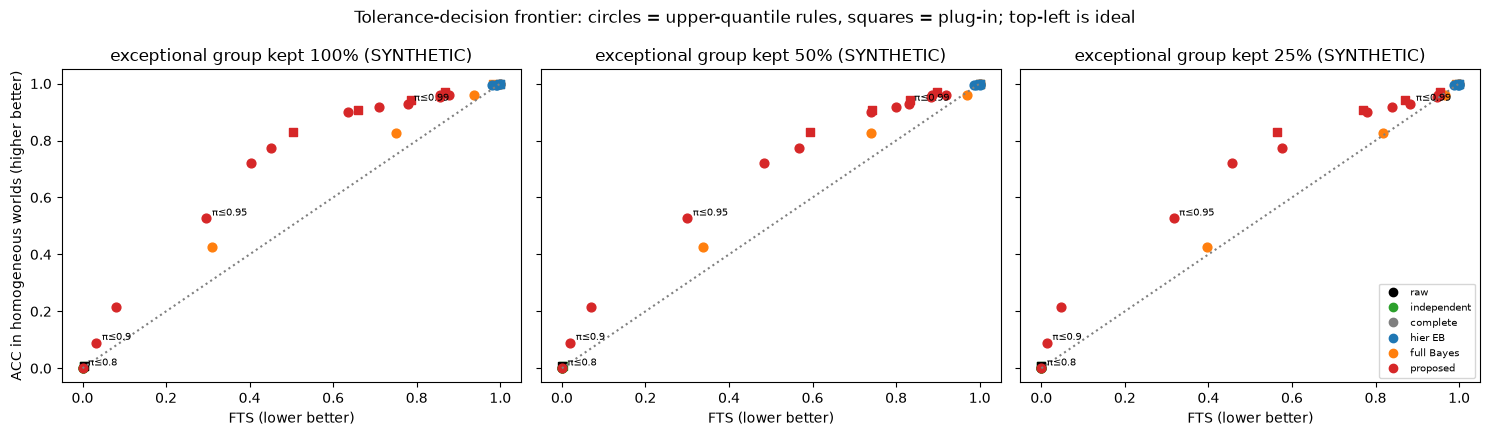

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for i, kp in enumerate([1.0, .5, .25]):
    a = ax[i]
    for (e, r), row in piv.iterrows():
        col = "C3" if e.startswith("robust") else {"hier": "C0", "fullbayes": "C1", "complete": "C7", "independent": "C2", "raw": "k"}[e]
        a.scatter(row[f"FTS keep={kp}"], row["ACC (homog.)"], c=col, marker="o" if r.startswith("upper") else "s", s=40)
        if e.startswith("robust") and r == "upper0.9": a.annotate(e.replace("robust@", "π≤"), (row[f"FTS keep={kp}"], row["ACC (homog.)"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
    a.plot([0, 1], [0, 1], ":", c="gray"); a.set_title(f"exceptional group kept {int(kp*100)}% (SYNTHETIC)"); a.set_xlabel("FTS (lower better)")
ax[0].set_ylabel("ACC in homogeneous worlds (higher better)")
from matplotlib.lines import Line2D
ax[2].legend(handles=[Line2D([], [], c=c_, marker="o", ls="", label=l) for c_, l in [("k", "raw"), ("C2", "independent"), ("C7", "complete"), ("C0", "hier EB"), ("C1", "full Bayes"), ("C3", "proposed")]], fontsize=7, loc="lower right")
plt.suptitle("Tolerance-decision frontier: circles = upper-quantile rules, squares = plug-in; top-left is ideal"); plt.tight_layout(); plt.savefig("figures/sim_frontier.png", dpi=160); plt.show()

**Findings, §8–§9 (SYNTHETIC).** (i) Exchangeable pooling masks the exceptional group almost always: hier declares
ΔEOpp ≤ 0.10 in 100% (plug-in) and 98% (upper 0.90) of the truly unfair worlds. The upper quantile does not rescue it,
because shrinkage moves the posterior *location* of the 20-positive group, not just the interval width. Fullbayes · upper0.9
reduces FTS to 0.31 but accepts only 43% of fair worlds. (ii) Raw and independent audits essentially never certify anything
(FTS ≈ 0, ACC ≤ 0.007): 8-positive groups make max−min noise-dominated. (iii) The contamination prior is the only family
above the diagonal. **The preregistered Youden rule selected `robust@0.8 · plugin`** (FTS 0.503, ACC 0.830, J = 0.327). The
runner-up `robust@0.8 · upper0.5` has J = 0.323, a difference well inside Monte Carlo error at R = 300. **So in this
calibration the upper-quantile rule did not improve on the posterior-mean rule.** This is a negative answer to the
secondary question about posterior uncertainty in threshold selection. (iv) No (estimator, rule) pair achieves both
FTS < 0.10 and ACC > 0.5. (v) Gap-interval coverage is 0.000 for hier, 0.038 for fullbayes and 0.264 for independent,
against 0.962 for robust@0.8 (whose intervals are also the widest, 0.399). Credible intervals are not frequentist guarantees.

### 9.1 Simulation robustness: group prevalence (base TPR), tolerance ε, slab prior, effect size δ

In [18]:
t1 = time.time(); robust_rows = []
EST_R = {"independent": {}, "hier": {}, "fullbayes": {}, PROPOSED["name"]: dict(pi_max=PROPOSED["pi_max"]) if PROPOSED["pi_max"] else {},
         "proposed_jeffreys_slab": dict(pi_max=PROPOSED["pi_max"] or .95, slab=(.5, .5))}
def _est_name(n_): return "robust" if n_.startswith(("robust", "proposed")) else n_
for base in (.35, .65, .85):
    for delta in (.15, .20, .30):
        sim = []
        rng = np.random.default_rng(int(base * 100 + delta * 1000))
        for scen in ("homogeneous", "exceptional"):
            for r in range(120):
                k, n, tt, ex = one_world(rng, scen, 1.0, base=base, delta=min(delta, base - .02))
                tg = tt.max() - tt.min()
                for name, kw in EST_R.items():
                    a = audit(k, n, _est_name(name), qs=QS, S=2000, rng=rng, **kw)
                    for eps in EPS_GRID:
                        rule_val = a[f"upper_{PROPOSED['q'] or .9}"]
                        sim.append(dict(base=base, delta=delta, scenario=scen, estimator=name, eps=eps, unfair=tg > eps,
                                        fair_upper=rule_val <= eps, fair_plugin=a["plugin_gap"] <= eps))
        sim = pd.DataFrame(sim)
        for (est, eps), g_ in sim.groupby(["estimator", "eps"]):
            u, f = g_[g_.unfair], g_[~g_.unfair]
            robust_rows.append(dict(base=base, delta=delta, estimator=est, eps=eps, FTS_upper=u.fair_upper.mean() if len(u) else np.nan,
                                    ACC_upper=f.fair_upper.mean() if len(f) else np.nan, FTS_plugin=u.fair_plugin.mean() if len(u) else np.nan,
                                    ACC_plugin=f.fair_plugin.mean() if len(f) else np.nan))
ROB = pd.DataFrame(robust_rows); ROB.to_csv("results/sim_robustness.csv", index=False); print(f"robustness simulation: {time.time()-t1:.0f}s")
CR = "plugin" if PROPOSED["rule"] == "plugin" else "upper"          # the rule frozen in §9
print(f"Rule frozen in §9: {PROPOSED['rule']} (columns *_{CR}); upper rule uses q = {PROPOSED['q'] or .9}")
for rl in ("plugin", "upper"):
    print(f"\nFTS ({rl} rule) at ε = {EPS}:"); print(ROB[ROB.eps == EPS].pivot_table(index="estimator", columns=["base", "delta"], values=f"FTS_{rl}").round(2).to_string())
    print(f"ACC ({rl} rule) at ε = {EPS}:"); print(ROB[ROB.eps == EPS].pivot_table(index="estimator", columns=["base", "delta"], values=f"ACC_{rl}").round(2).to_string())
print("\nFTS and ACC by tolerance ε (averaged over prevalence and δ):")
print(ROB.pivot_table(index="estimator", columns="eps", values=["FTS_plugin", "ACC_plugin", "FTS_upper", "ACC_upper"]).round(3).to_string())

robustness simulation: 155s
Rule frozen in §9: plugin (columns *_plugin); upper rule uses q = 0.9

FTS (plugin rule) at ε = 0.1:
base                    0.35              0.65              0.85            
delta                   0.15  0.20  0.30  0.15  0.20  0.30  0.15  0.20  0.30
estimator                                                                   
fullbayes               1.00  0.99  0.98  0.99  0.99  0.98  0.98  0.93  0.89
hier                    1.00  1.00  1.00  0.99  1.00  1.00  1.00  0.98  0.99
independent             0.00  0.01  0.00  0.00  0.00  0.00  0.00  0.00  0.00
proposed_jeffreys_slab  0.62  0.48  0.07  0.65  0.54  0.30  0.67  0.49  0.19
robust@0.8              0.65  0.49  0.08  0.62  0.49  0.30  0.62  0.44  0.16
ACC (plugin rule) at ε = 0.1:
base                    0.35              0.65              0.85            
delta                   0.15  0.20  0.30  0.15  0.20  0.30  0.15  0.20  0.30
estimator                                                              

**Findings, §9.1 (SYNTHETIC).** The frozen rule (robust@0.8 · plugin) depends strongly on effect size. At ε = 0.10, FTS falls
from 0.62–0.65 (δ = 0.15) through 0.44–0.49 (δ = 0.20) to 0.08–0.30 (δ = 0.30), with ACC 0.72–0.92. hier and fullbayes plug-in
stay at FTS ≥ 0.89 in every cell. The Jeffreys slab Beta(½, ½) behaves like the Beta(1, 1) slab (mean FTS 0.444 vs 0.427,
ACC 0.836 vs 0.819). Tightening ε trades acceptance for safety: for robust@0.8 · plugin, FTS is 0.215/0.427/0.552 and ACC is
0.561/0.819/0.919 at ε = 0.05/0.10/0.15. Its upper-0.90 variant almost never certifies (ACC ≤ 0.07).

### 9.2 Semi-synthetic simulation on the real CA intersection design — **SEMI-SYNTHETIC** (out-of-sample check of §9)
§8 used an invented 16-group design. Here the design is **real**: the 32 non-empty intersections of the seed-0
**validation** split and their positive counts (1 to 5,499; `VAL_POS` from §6.1). Only the TPRs θ_g are invented, so
every result in this subsection is a property of the procedures on this design, **not a fact about California**.
The calibrated procedure is the one frozen in §9 (`PROPOSED`). It is **not** re-chosen here, so this is an
out-of-sample check of the §9 calibration on a design that the calibration never saw.

| World | True θ_g | Deficit set | Truly unfair at ε = 0.10? |
|---|---|---|---|
| homogeneous | 0.38 + U(−0.015, 0.015) for every g | none | no (gap ≤ 0.03) |
| exceptional: cell | homogeneous, but θ(2\|2\|1) = 0.38 − 0.20 (Black, female, disabled; 24 positives) | {2\|2\|1} | yes |
| exceptional: interaction only | as *cell*, then the other 31 groups are moved by the minimum-norm amount that makes every race, sex and disability margin (positive-weighted mean TPR) exactly 0.38, so **all main effects are equal** and the deficit is a pure interaction that single-attribute audits cannot see | {2\|2\|1} | yes |
| exceptional: disability main effect | homogeneous, minus 0.20 for **every** DIS = 1 group, so 2\|2\|1 is low because it is disabled | all DIS = 1 groups | yes |

The positives of 2|2|1 are thinned to 100%, 50% and 25% (24 → 12 → 6) in every world. k_g ~ Bin(n_g, θ_g), and R = 300
replicates per cell. Estimators: raw, independent, hier, fullbayes, struct (each with the plug-in rule and the upper-q
rule, q = the §9 quantile) and the **calibrated proposed procedure**. **FTS** = P(declared fair | truly unfair),
**ACC** = P(declared fair | truly fair), **coverage/width** = central 90% interval of the max−min gap,
**cov θ(2|2|1)** = 90% interval coverage for the exceptional group's own TPR, and **ex_worst** = P(the group ranked worst by
posterior mean is in the deficit set).

In [19]:
R_SEMI = 300
I221, DIS1 = int(np.where(VAL_LAB == "2|2|1")[0][0]), np.array([l.split("|")[2] == "1" for l in VAL_LAB])
A_MARG = np.array([(np.array([l.split("|")[j] for l in VAL_LAB]) == lv) * VAL_N / VAL_N[np.array([l.split("|")[j] for l in VAL_LAB]) == lv].sum()
                   for j in range(3) for lv in np.unique([l.split("|")[j] for l in VAL_LAB])])     # positive-weighted margins
def semi_world(rng, world, keep, base=.38, spread=.03, delta=.20):
    t = base + rng.uniform(-spread / 2, spread / 2, len(VAL_N)); deficit = np.zeros(len(VAL_N), bool)
    if world in ("cell", "interaction"): t[I221] = base - delta; deficit[I221] = True
    if world == "interaction":                     # minimum-norm shift of the other groups so that every margin equals base
        free = np.arange(len(VAL_N)) != I221
        t[free] += np.linalg.lstsq(A_MARG[:, free], base - A_MARG @ t, rcond=None)[0]
        assert np.allclose(A_MARG @ t, base, atol=1e-9)
    if world == "dis_main": t[DIS1] -= delta; deficit = DIS1.copy()
    n = VAL_N.copy(); n[I221] = max(1, round(n[I221] * keep))
    return rng.binomial(n.astype(int), t), n, t, deficit

SEMI_EST = {"raw": ("raw", {}), "independent": ("independent", {}), "hier": ("hier", {}), "fullbayes": ("fullbayes", {}),
            "struct": ("struct", {}), "proposed": (PROP_EST, PROP_KW)}
SEMI_WORLDS = [(w, kp) for w in ("homogeneous", "cell", "interaction", "dis_main") for kp in (1.0, .5, .25)]
t1 = time.time(); rng = np.random.default_rng(2024); semi_rows, shift_max = [], []
for world, kp in SEMI_WORLDS:
    for r in range(R_SEMI):
        k, n, tt, deficit = semi_world(rng, world, kp); tg = tt.max() - tt.min()
        if world == "interaction": shift_max.append(np.abs(np.delete(tt, I221) - .38).max())
        for name, (est, kw) in SEMI_EST.items():
            a = audit(k, n, est, qs=(QSEL,), S=2000, rng=rng, labels=VAL_LAB, **kw)
            base_ = dict(world=world, keep=kp, estimator=name, rep=r, true_gap=tg, truly_unfair=tg > EPS,
                         ex_worst=float(deficit[np.argmin(a["means"])]) if deficit.any() else np.nan)
            rules = [("plugin", a["plugin_gap"])] + ([(f"upper{QSEL}", a[f"upper_{QSEL}"])] if est != "raw" else [])
            extra = {}
            if est != "raw":
                lo, hi = a["ci90"]; l2, h2 = np.quantile(a["samples"][:, I221], [.05, .95])
                extra = dict(covered=float(lo <= tg <= hi), width=hi - lo, cov_221=float(l2 <= tt[I221] <= h2), mean_221=a["means"][I221])
            for rule, val in rules:
                if name == "proposed" and rule != PROPOSED["rule"]: continue      # the calibrated procedure is a single (estimator, rule)
                semi_rows.append(dict(base_, rule=rule, declared_fair=val <= EPS, **extra))
SEMI = pd.DataFrame(semi_rows); SEMI.to_csv("results/semisynthetic_raw.csv", index=False)
print(f"semi-synthetic simulation: {time.time()-t1:.0f}s, {R_SEMI} replicates x {len(SEMI_WORLDS)} cells")
print(f"interaction-only world: max |θ_g − 0.38| over the other 31 groups after the margin projection: mean {np.mean(shift_max):.4f}, max {np.max(shift_max):.4f}")
print(f"true gap > ε in every exceptional replicate: {bool(SEMI[SEMI.world != 'homogeneous'].truly_unfair.all())}; "
      f"in no homogeneous replicate: {not SEMI[SEMI.world == 'homogeneous'].truly_unfair.any()}")
SEMI["procedure"] = np.where(SEMI.estimator == "proposed", f"PROPOSED ({PROPOSED['name']}, {PROPOSED['rule']})", SEMI.estimator + " · " + SEMI.rule)
SEMIS = SEMI.groupby(["world", "keep", "procedure"]).agg(declared_fair=("declared_fair", "mean"), coverage90=("covered", "mean"), width90=("width", "mean"),
                                                      cov_theta_221=("cov_221", "mean"), mean_theta_221=("mean_221", "mean"), ex_worst=("ex_worst", "mean"), reps=("rep", "count")).reset_index()
SEMIS.to_csv("results/semisynthetic_summary.csv", index=False)
pv = SEMIS.pivot_table(index="procedure", columns=["world", "keep"], values="declared_fair")
pv.columns = [("ACC " if w == "homogeneous" else f"FTS {w} ") + f"keep={kp}" for w, kp in pv.columns]
print("\nDeclared-fair rates (FTS: lower is better; ACC: higher is better):"); print(pv.round(3).to_string())
print("\nCoverage / width of the 90% gap interval, coverage of θ(2|2|1), and P(worst-ranked group ∈ deficit set), by world (mean over thinning levels):")
print(SEMIS[SEMIS.world != "homogeneous"].pivot_table(index="procedure", columns="world", values=["coverage90", "width90", "cov_theta_221", "ex_worst"]).round(3).to_string())
print("\nBy thinning level (exceptional: cell):")
print(SEMIS[SEMIS.world == "cell"].pivot_table(index="procedure", columns="keep", values=["coverage90", "cov_theta_221", "mean_theta_221", "ex_worst"]).round(3).to_string())
pp = SEMIS[SEMIS.procedure.str.startswith("PROPOSED")].set_index(["world", "keep"]).declared_fair
print(f"\nOut-of-sample check of §9: calibrated procedure had FTS {CAL_FTS:.3f} / ACC {CAL_ACC:.3f} on the synthetic design (keep=1); "
      f"on the real design FTS(cell) {pp[('cell', 1.0)]:.3f}, FTS(interaction) {pp[('interaction', 1.0)]:.3f}, FTS(dis_main) {pp[('dis_main', 1.0)]:.3f}, ACC {pp[('homogeneous', 1.0)]:.3f}")

semi-synthetic simulation: 482s, 300 replicates x 12 cells
interaction-only world: max |θ_g − 0.38| over the other 31 groups after the margin projection: mean 0.0159, max 0.0263
true gap > ε in every exceptional replicate: True; in no homogeneous replicate: True

Declared-fair rates (FTS: lower is better; ACC: higher is better):
                               FTS cell keep=0.25  FTS cell keep=0.5  FTS cell keep=1.0  FTS dis_main keep=0.25  FTS dis_main keep=0.5  FTS dis_main keep=1.0  ACC keep=0.25  ACC keep=0.5  ACC keep=1.0  FTS interaction keep=0.25  FTS interaction keep=0.5  FTS interaction keep=1.0
procedure                                                                                                                                                                                                                                                                              
PROPOSED (robust@0.8, plugin)               0.280              0.197              0.133                     0

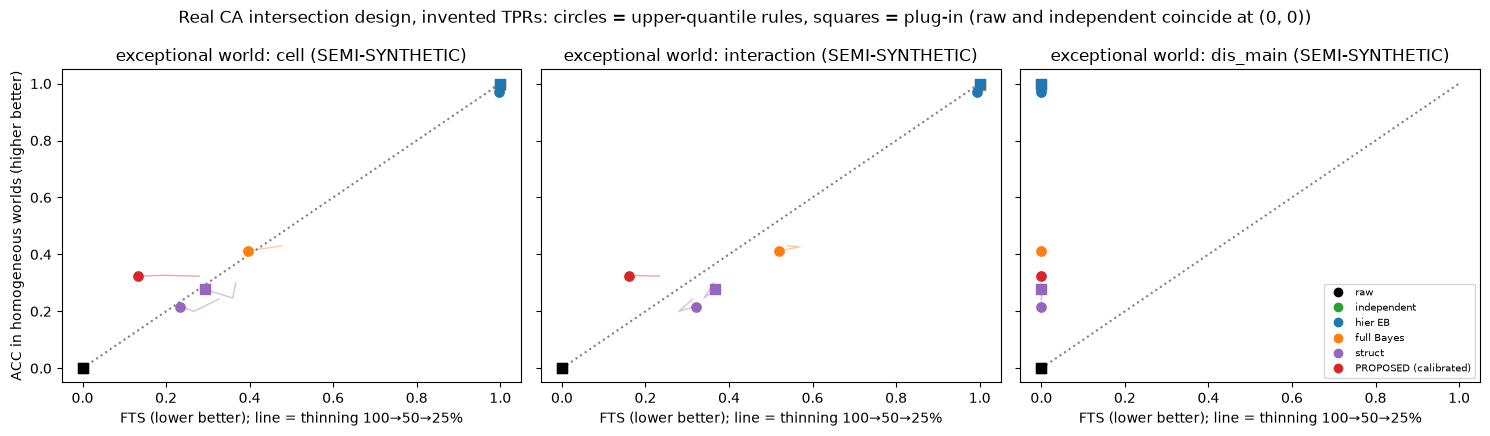

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
procs = [p_ for p_ in pv.index]; colmap = {"raw": "k", "independent": "C2", "hier": "C0", "fullbayes": "C1", "struct": "C4"}
for i, w in enumerate(["cell", "interaction", "dis_main"]):
    a = ax[i]
    for p_ in procs:
        xs = [pv.loc[p_, f"FTS {w} keep={kp}"] for kp in (1.0, .5, .25)]; ys = [pv.loc[p_, f"ACC keep={kp}"] for kp in (1.0, .5, .25)]
        c_ = "C3" if p_.startswith("PROPOSED") else colmap[p_.split(" · ")[0]]
        a.plot(xs, ys, "-", c=c_, alpha=.4, lw=1); a.scatter(xs[0], ys[0], c=c_, marker="o" if ("upper" in p_ or p_.startswith("PROPOSED")) else "s", s=45, zorder=3)
    a.plot([0, 1], [0, 1], ":", c="gray"); a.set_title(f"exceptional world: {w} (SEMI-SYNTHETIC)"); a.set_xlabel("FTS (lower better); line = thinning 100→50→25%")
ax[0].set_ylabel("ACC in homogeneous worlds (higher better)")
ax[2].legend(handles=[Line2D([], [], c=c_, marker="o", ls="", label=l) for c_, l in [("k", "raw"), ("C2", "independent"), ("C0", "hier EB"), ("C1", "full Bayes"),
             ("C4", "struct"), ("C3", "PROPOSED (calibrated)")]], fontsize=7, loc="lower right")
plt.suptitle("Real CA intersection design, invented TPRs: circles = upper-quantile rules, squares = plug-in (raw and independent coincide at (0, 0))"); plt.tight_layout()
plt.savefig("figures/semisynthetic_frontier.png", dpi=160); plt.show()

**Findings, §9.2 (SEMI-SYNTHETIC; properties of the procedures on the real design, not facts about California).**
1. **Exchangeable pooling still masks a real-sized exception.** With 2|2|1 at 0.18 (24 positives), hier declares
   "fair" in 98–100% of unfair worlds under both rules. Its posterior mean for 2|2|1 is 0.378–0.379, i.e. the group is
   pulled all the way to the majority, and its 90% interval for θ(2|2|1) never covers the truth.
2. **The attribute-structured baseline masks it too.** In the cell and interaction-only worlds the Black, female and
   disabled main effects are ≈ 0, so `struct` shrinks 2|2|1 toward 0.38 (mean 0.368–0.377). Its θ(2|2|1) interval coverage is
   0.000 and its gap interval is only ≈ 0.011 wide, with coverage 0.01–0.02. FTS is 0.23–0.37 and ACC 0.20–0.30, so it is poor
   on both axes, because τ̂ hits its lower bound and the plug-in ignores β̂ uncertainty (see §6.1).
3. **Interaction-only vs cell.** Removing every main effect exactly (the 31 other groups shift by 0.016 on average) changes
   little. Fullbayes · upper FTS rises from 0.40–0.48 to 0.52–0.57 and the proposed procedure's from 0.13–0.28 to 0.16–0.23.
4. **Disability main effect.** When the deficit is shared by all sixteen DIS = 1 groups (including two with ~300 positives),
   **every** estimator detects it (FTS = 0). Pooling only hides deficits that are confined to small groups.
5. **Calibrated procedure, out of sample.** robust@0.8 · plugin has FTS 0.133/0.197/0.280 (cell; keep 1/0.5/0.25),
   0.160/0.160/0.233 (interaction) and 0 (disability), so thinning raises false claims. **But its ACC is only 0.32–0.33,
   against 0.830 in the §9 calibration.** With 32 groups, many of them tiny, some group escapes pooling in most homogeneous
   worlds and widens the plug-in gap. **The §9 operating point does not transfer to the real design**: the calibration is
   design-specific and has to be redone on the deployment design. This is a negative result.
6. Its θ(2|2|1) interval covers 0.58–0.72 and its gap interval 0.89–0.99, and the deficit group is ranked worst in 33–61% of
   replicates, more often than under any pooled estimator (≤ 6%) and close to the independent estimator (40–64%).

## 10. Experiments 2 and 5 — minority thinning and ordinary vs uncertainty-aware threshold selection
**Rule family R(λ)**: per-group thresholds t_g(λ) = (1−λ)·t_global + λ·t_g^EOpp + c, with c set by bisection so the
overall outreach rate is exactly 30% (matched capacity). λ = 0 is the group-unaware rule; λ = 1 is ordinary
opportunity-constrained threshold adjustment. Selection uses **validation only**: maximise recall subject to
criterion ≤ ε, else take the λ with the smallest criterion. The frozen rule is audited on the untouched test split,
with both empirical and model-based estimates.

Thinning removes a fraction of the selected intersections from **training and validation only**
(Black female disabled, Black male disabled, Asian female disabled); the test split is intact.

In [21]:
THIN_GROUPS = ["2|2|1", "2|1|1", "6|2|1"]; THIN_LEVELS = [1.0, .5, .25, .10]; LAMS = np.linspace(0, 1, 11)
CRITERIA = {"raw_plugin": ("raw", {}, "plugin"), "independent_upper": ("independent", {}, "upper"), "complete_plugin": ("complete", {}, "plugin"),
            "hier_plugin": ("hier", {}, "plugin"), "hier_upper": ("hier", {}, "upper"), "fullbayes_upper": ("fullbayes", {}, "upper"),
            "struct_plugin": ("struct", {}, "plugin"), "struct_upper": ("struct", {}, "upper"),
            "proposed_plugin": (PROP_EST, PROP_KW, "plugin"), "proposed_upper": (PROP_EST, PROP_KW, "upper")}

def thresholds(s, y, g, lam, cap=CAP):
    tg = np.quantile(s, 1 - cap); tau = (s[y == 1] >= tg).mean(); groups = np.unique(g)
    teo = {gg: (np.quantile(s[(g == gg) & (y == 1)], 1 - tau) if ((g == gg) & (y == 1)).sum() else tg) for gg in groups}
    base = np.array([(1 - lam) * tg + lam * teo[x] for x in g]); lo, hi = -2., 2.
    for _ in range(60):
        cc = (lo + hi) / 2
        if (s >= base + cc).mean() > cap: lo = cc
        else: hi = cc
    return {gg: (1 - lam) * tg + lam * teo[gg] + cc for gg in groups}, tg

def apply_thr(s, g, thr, default): return (s >= np.array([thr.get(x, default) for x in g])).astype(int)

def select_all(sv, yv, gv, rng, eps=EPS):
    per_lam = []
    for lam in LAMS:
        thr, tg = thresholds(sv, yv, gv, lam); d = apply_thr(sv, gv, thr, tg); T = group_table(yv, d, gv)
        crit, fits = {}, {}
        for cname, (est, kw, rule) in CRITERIA.items():      # one posterior per (estimator, prior); plugin and upper share it
            key = (est, tuple(sorted(kw.items())))
            if key not in fits: fits[key] = audit(T.k.values, T.n_pos.values, est, eps=eps, qs=(QSEL,), S=3000, rng=rng, labels=T.index.values, **kw)
            crit[cname] = fits[key]["plugin_gap"] if rule == "plugin" else fits[key][f"upper_{QSEL}"]
        per_lam.append(dict(lam=lam, thr=thr, tg=tg, recall=d[yv == 1].mean(), **crit))
    chosen = {}
    for cname in CRITERIA:
        ok = [r for r in per_lam if r[cname] <= eps]
        chosen[cname] = max(ok, key=lambda r: r["recall"]) if ok else min(per_lam, key=lambda r: r[cname])
    return chosen, per_lam

t1 = time.time(); SEL, CURVES, DEC, DEC_LAM = [], [], {}, {}
for s in SEEDS:
    tr, va, te = household_split(df, s)
    for kf in THIN_LEVELS:
        trk, vak = tr, va
        if kf < 1:
            r_ = np.random.default_rng(1000 + s)
            trk = tr[~(tr.G.isin(THIN_GROUPS) & (r_.random(len(tr)) > kf))].reset_index(drop=True)
            vak = va[~(va.G.isin(THIN_GROUPS) & (r_.random(len(va)) > kf))].reset_index(drop=True)
        sv, st = fit_all(trk, vak, te, s, which=("BN",))["BN"]; rng = np.random.default_rng(s)
        chosen, per_lam = select_all(sv, vak.Y.values, vak.G.values, rng)
        for r in per_lam:   # trade-off curves (validation and test)
            dte = apply_thr(st, te.G.values, r["thr"], r["tg"]); fm = fairness_metrics(te.Y.values, dte, te.G.values)
            CURVES.append(dict(seed=s, keep=kf, lam=r["lam"], val_recall=r["recall"], val_gap_raw=r["raw_plugin"], test_recall=dte[te.Y.values == 1].mean(), test_dEOpp=fm["dEOpp"]))
        for cname, r in chosen.items():
            d = apply_thr(st, te.G.values, r["thr"], r["tg"]); T = group_table(te.Y.values, d, te.G.values)
            pa = audit(T.k.values, T.n_pos.values, PROP_EST, qs=(QSEL,), rng=rng, labels=T.index.values, **PROP_KW)   # model-based test audits
            ps = audit(T.k.values, T.n_pos.values, "struct", qs=(QSEL,), rng=rng, labels=T.index.values)
            fm = fairness_metrics(te.Y.values, d, te.G.values)
            thin_tpr = T.loc[T.index.isin(THIN_GROUPS), "t_g"].mean()
            SEL.append(dict(seed=s, keep=kf, criterion=cname, lam=r["lam"], val_criterion=r[cname], val_feasible=r[cname] <= EPS,
                            test_recall=d[te.Y.values == 1].mean(), test_sel_rate=d.mean(), test_model_upper=pa[f"upper_{QSEL}"],
                            test_P_exceed=pa["p_exceed"], test_struct_upper=ps[f"upper_{QSEL}"], test_struct_P_exceed=ps["p_exceed"],
                            thinned_groups_mean_tpr=thin_tpr, **{f"test_{k}": v for k, v in fm.items()}))
            if s == 0 and kf == 1.0: DEC[cname] = (d, te); DEC_LAM[cname] = round(float(r["lam"]), 2)
SEL = pd.DataFrame(SEL); SEL.to_csv("results/selection_all.csv", index=False); CURVES = pd.DataFrame(CURVES); CURVES.to_csv("results/tradeoff_curves.csv", index=False)
print(f"selection experiments: {time.time()-t1:.0f}s")
cols = ["lam", "val_feasible", "test_recall", "test_sel_rate", "test_dEOpp", "test_dEOdds", "test_dDP", "test_R_sel", "test_worst_recall",
        "test_model_upper", "test_P_exceed", "test_struct_upper", "test_struct_P_exceed", "thinned_groups_mean_tpr"]
print(SEL.groupby(["keep", "criterion"])[cols].mean().round(3).to_string())

selection experiments: 124s
                         lam  val_feasible  test_recall  test_sel_rate  test_dEOpp  test_dEOdds  test_dDP  test_R_sel  test_worst_recall  test_model_upper  test_P_exceed  test_struct_upper  test_struct_P_exceed  thinned_groups_mean_tpr
keep criterion                                                                                                                                                                                                                             
0.10 complete_plugin    0.18           1.0        0.384          0.293       0.692        0.692     0.626       0.006              0.003             0.708          1.000              0.695                   1.0                    0.070
     fullbayes_upper    1.00           1.0        0.377          0.296       0.410        0.410     0.392       0.139              0.196             0.680          0.962              0.431                   1.0                    0.383
     hier_plugin        0.90

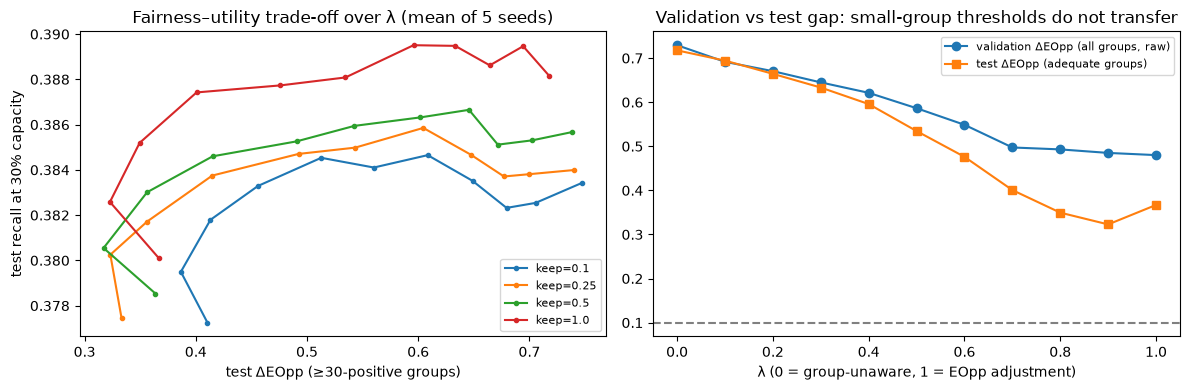

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kf, g_ in CURVES.groupby("keep"):
    m_ = g_.groupby("lam").mean(numeric_only=True); ax[0].plot(m_.test_dEOpp, m_.test_recall, "o-", ms=3, label=f"keep={kf}")
ax[0].set_xlabel("test ΔEOpp (≥30-positive groups)"); ax[0].set_ylabel("test recall at 30% capacity"); ax[0].set_title("Fairness–utility trade-off over λ (mean of 5 seeds)"); ax[0].legend(fontsize=8)
m_ = CURVES[CURVES.keep == 1.0].groupby("lam").mean(numeric_only=True)
ax[1].plot(m_.index, m_.val_gap_raw, "o-", label="validation ΔEOpp (all groups, raw)"); ax[1].plot(m_.index, m_.test_dEOpp, "s-", label="test ΔEOpp (adequate groups)")
ax[1].axhline(EPS, ls="--", c="gray"); ax[1].set_xlabel("λ (0 = group-unaware, 1 = EOpp adjustment)"); ax[1].set_title("Validation vs test gap: small-group thresholds do not transfer"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/tradeoff_curves.png", dpi=160); plt.show()

**Findings, §10 (real data; 5 household splits × 4 thinning levels).**
- **Validation feasibility.** The pooled criteria hier_plugin, hier_upper, fullbayes_upper, complete_plugin and the calibrated
  proposed_plugin **find a λ with criterion ≤ 0.10 on validation in every split and thinning level**. struct does so in 2 of
  5 splits. raw_plugin, independent_upper and proposed_upper (π ≤ 0.8, q = 0.90) never do, and use the fallback
  (minimum-criterion λ). *This corrects an earlier write-up that said no λ was feasible under any criterion. The original
  handoff code gives the same feasibility at seed 0.*
- **Each of those 116 validation-time "tolerance satisfied" declarations is false on the independent test split.** The empirical
  test ΔEOpp over groups with ≥ 30 positives is 0.227–0.770 for these rules, never ≤ 0.10, and the model-based test audit gives
  P(ΔEOpp > 0.10) ≥ 0.81 for each. At keep = 1, mean test ΔEOpp is 0.323 (hier_plugin), 0.332 (proposed_plugin),
  0.348 (raw_plugin), 0.367 (hier_upper, fullbayes_upper, struct, proposed_upper), 0.418 (independent_upper) and
  0.641 (complete_plugin; complete pooling certifies every λ). Part of the problem is pooling and part is that
  validation-fitted group thresholds for small intersections do not transfer: the raw validation gap at λ = 1 is 0.48.
- **Utility.** Capacity is matched exactly on validation, and test selection rates are 0.292–0.305. Mean test recall is 0.388
  at λ = 0 and 0.380 at λ = 1, a cost of 0.008, within the preregistered 0.02 budget. Under thinning to 10%, mean test ΔEOpp
  rises to 0.376–0.410 for the partial-pooling criteria (0.692 for complete pooling).

## 11. Confirmatory tests: paired household-cluster bootstrap + Holm, and refit (training) uncertainty
Fixed-model bootstrap (seed 0, B = 1000 household-level Poisson bootstrap) measures *evaluation* uncertainty.
The spread across the 5 refitted splits measures *training* uncertainty (protocol 6). Both are reported.

In [23]:
CAL_CRIT = "proposed_plugin" if PROPOSED["rule"] == "plugin" else "proposed_upper"     # the procedure frozen in §9 (QSEL = its q)
print("confirmatory arm = calibrated procedure:", CAL_CRIT, PROPOSED)
d_ref, te_ref = DEC[CAL_CRIT]; y, g = te_ref.Y.values, te_ref.G.values
hh = pd.factorize(te_ref.SERIALNO)[0]; Hn = hh.max() + 1; T_ = group_table(y, d_ref, g); okg = T_.index[T_.n_pos >= MIN_SUPPORT]
mask = np.isin(g, okg); _, gi = np.unique(g[mask], return_inverse=True); G_ = gi.max() + 1
def bstats(w, d):
    w, yy, dd = w[mask], y[mask], d[mask]
    t = np.bincount(gi, w * yy * dd, G_) / np.maximum(np.bincount(gi, w * yy, G_), 1e-9)
    return np.array([t.max() - t.min(), (w * yy * dd).sum() / (w * yy).sum()])
rb = np.random.default_rng(7); W = [rb.poisson(1, Hn)[hh].astype(float) for _ in range(B_BOOT)]
pairs = [(CAL_CRIT, "hier_plugin"), (CAL_CRIT, "raw_plugin")]                          # preregistered Holm family
explo = [(c_, b_) for c_ in ("proposed_upper", "proposed_plugin", "struct_upper", "struct_plugin") if c_ != CAL_CRIT for b_ in ("hier_plugin", "raw_plugin")]
out = []
for a_, b_ in pairs + explo:
    diff = np.array([bstats(w, DEC[a_][0]) - bstats(w, DEC[b_][0]) for w in W]); pt = bstats(np.ones(len(y)), DEC[a_][0]) - bstats(np.ones(len(y)), DEC[b_][0])
    for j, name in enumerate(["dEOpp", "recall"]):
        lo, hi = np.quantile(diff[:, j], [.025, .975]); p = min(1., max(2 * min((diff[:, j] <= 0).mean(), (diff[:, j] >= 0).mean()), 1 / B_BOOT))
        sd_pool = np.std(diff[:, j]); out.append(dict(comparison=f"{a_} − {b_}", family="confirmatory" if (a_, b_) in pairs else "exploratory",
                                                       metric=name, estimate=pt[j], lo95=lo, hi95=hi, p_boot=p,
                                                       effect_size_d=pt[j] / sd_pool if sd_pool > 0 else np.nan))
BT = pd.DataFrame(out); gp = BT[(BT.metric == "dEOpp") & (BT.family == "confirmatory")].sort_values("p_boot")
BT.loc[gp.index, "p_holm"] = np.minimum(1, np.maximum.accumulate([p * (len(gp) - i) for i, p in enumerate(gp.p_boot)]))
BT.to_csv("results/confirmatory_bootstrap.csv", index=False)
print("EVALUATION uncertainty (seed-0 fitted model, household-cluster bootstrap; Holm only within the confirmatory ΔEOpp family):")
print(BT.round(4).to_string(index=False))
print("\nλ chosen on validation at seed 0:", {c_: DEC_LAM[c_] for c_ in sorted(set(sum(pairs + explo, ())))})
refit = SEL[SEL.keep == 1.0].pivot_table(index="seed", columns="criterion", values="test_dEOpp")
refit_rec = SEL[SEL.keep == 1.0].pivot_table(index="seed", columns="criterion", values="test_recall")
print("\nTRAINING (refit) uncertainty — test ΔEOpp per household split (5 refits):")
print(refit[[CAL_CRIT, "proposed_upper" if CAL_CRIT != "proposed_upper" else "proposed_plugin", "struct_upper", "struct_plugin", "hier_plugin", "raw_plugin"]].round(3).to_string())
for nm_, tb_ in (("ΔEOpp", refit), ("recall", refit_rec)):
    print(f"paired refit differences in test {nm_} (mean ± sd over 5 splits; sign of each split):",
          {f"{a}−{b}": f"{(tb_[a]-tb_[b]).mean():+.4f} ± {(tb_[a]-tb_[b]).std():.4f}  signs {''.join('+' if v > 1e-12 else ('-' if v < -1e-12 else '0') for v in tb_[a]-tb_[b])}" for a, b in pairs})

confirmatory arm = calibrated procedure: proposed_plugin {'name': 'robust@0.8', 'pi_max': 0.8, 'q': None, 'rule': 'plugin'}


EVALUATION uncertainty (seed-0 fitted model, household-cluster bootstrap; Holm only within the confirmatory ΔEOpp family):
                   comparison       family metric  estimate    lo95    hi95  p_boot  effect_size_d  p_holm
proposed_plugin − hier_plugin confirmatory  dEOpp    0.0000  0.0000  0.0000   1.000            NaN   1.000
proposed_plugin − hier_plugin confirmatory recall    0.0000  0.0000  0.0000   1.000            NaN     NaN
 proposed_plugin − raw_plugin confirmatory  dEOpp   -0.0517 -0.1944  0.0505   0.368        -0.7898   0.736
 proposed_plugin − raw_plugin confirmatory recall   -0.0061 -0.0089 -0.0035   0.001        -4.1469     NaN
 proposed_upper − hier_plugin  exploratory  dEOpp   -0.0714 -0.1755  0.0000   0.074        -1.6177     NaN
 proposed_upper − hier_plugin  exploratory recall   -0.0026 -0.0048 -0.0005   0.014        -2.3722     NaN
  proposed_upper − raw_plugin  exploratory  dEOpp   -0.1231 -0.3073  0.0091   0.076        -1.5316     NaN
  proposed_upper − ra

**Findings, §11.** *Evaluation uncertainty* (seed-0 fitted model, 1,000 household-cluster bootstrap replicates):
the calibrated procedure and hier_plugin chose the same λ = 0.9, so their test decisions are identical (Δ = 0, Holm p = 1).
Against raw_plugin (λ = 0.7), test ΔEOpp differs by −0.052, 95% CI [−0.194, 0.051], Holm p = 0.736. Recall differs by
−0.006 [−0.0089, −0.0035], a statistically clear but negligible cost. **Neither confirmatory comparison is significant.**
Exploratory: proposed_upper − raw_plugin is −0.123 [−0.307, 0.009], p = 0.076, so the earlier seed-0 result (Holm p = 0.04) does
not reproduce. *Training uncertainty* (5 refits): calibrated − raw_plugin is −0.016 ± 0.039 (signs − + − 0 −) and
calibrated − hier_plugin is +0.009 ± 0.035 (0 + + − 0). There is no consistent direction across refits.

## 12. Real-data robustness: tolerance ε, prior strength / slab, thinning (seed 0)

In [24]:
rr = []; tr, va, te = household_split(df, 0); sv, st = fit_all(tr, va, te, 0, which=("BN",))["BN"]; d = topcap(sv, st); T = group_table(te.Y.values, d, te.G.values)
for eps in EPS_GRID:
    for name, (est, kw) in {"hier": ("hier", {}), "fullbayes": ("fullbayes", {}), "struct": ("struct", {}), "proposed π≤0.80": ("robust", dict(pi_max=.8)),
                            "proposed π≤0.90": ("robust", dict(pi_max=.9)), "proposed π≤0.95": ("robust", dict(pi_max=.95)), "proposed π≤0.99": ("robust", dict(pi_max=.99)),
                            "proposed Jeffreys slab": ("robust", dict(pi_max=PROPOSED["pi_max"] or .95, slab=(.5, .5)))}.items():
        a = audit(T.k.values, T.n_pos.values, est, eps=eps, qs=(QSEL,), rng=np.random.default_rng(0), labels=T.index.values, **kw)
        rr.append(dict(eps=eps, estimator=name, plugin_gap=a["plugin_gap"], upper=a[f"upper_{QSEL}"], P_exceed=a["p_exceed"],
                       declared_fair_plugin=a["plugin_gap"] <= eps, declared_fair_upper=a[f"upper_{QSEL}"] <= eps))
print("Seed-0 unconstrained BN rule, test counts; upper = q-quantile with q =", QSEL); print(pd.DataFrame(rr).round(3).to_string(index=False))

Seed-0 unconstrained BN rule, test counts; upper = q-quantile with q = 0.9
 eps              estimator  plugin_gap  upper  P_exceed  declared_fair_plugin  declared_fair_upper
0.05                   hier       0.736  0.792       1.0                 False                False
0.05              fullbayes       0.736  0.800       1.0                 False                False
0.05                 struct       0.754  0.756       1.0                 False                False
0.05        proposed π≤0.80       0.732  0.817       1.0                 False                False
0.05        proposed π≤0.90       0.736  0.802       1.0                 False                False
0.05        proposed π≤0.95       0.736  0.797       1.0                 False                False
0.05        proposed π≤0.99       0.732  0.817       1.0                 False                False
0.05 proposed Jeffreys slab       0.736  0.815       1.0                 False                False
0.10                   hi

**Findings, §12.** For the unconstrained rule, every estimator and prior (π_max 0.80–0.99, Jeffreys slab, struct) gives
P(ΔEOpp > ε) = 1.0 and declares the tolerance violated at every ε ∈ {0.05, 0.10, 0.15}. The conclusion is insensitive to
prior and tolerance because the gap (≈ 0.73–0.75) is far beyond ε.

## 13. Survey-weighted estimand (replicate-weight standard errors)
Primary results describe the benchmark sample. For a population statement, person weights PWGTP and the 80
successive-difference replicate weights give Var(θ̂) = (4/80)·Σ_r (θ̂_r − θ̂)². Ratios such as TPR are invariant to
the test-split subsampling of households, so weights need no rescaling for these quantities.

In [25]:
def wtpr(w, mk): return (w[mk] * d[mk]).sum() / w[mk].sum()
rowsw = []; pos = te.Y.values == 1
for gg in ["1|1", "1|2", "2|1", "2|2"]:
    mk = pos & ((te.SEXc + "|" + te.DISc).values == gg); est = wtpr(te.PWGTP.values, mk)
    reps = np.array([wtpr(te[f"PWGTP{i}"].values, mk) for i in range(1, 81)])
    rowsw.append(dict(group=f"SEX|DIS={gg}", n_pos=int(mk.sum()), unweighted_TPR=d[mk].mean(), weighted_TPR=est, replicate_SE=np.sqrt(4 / 80 * ((reps - est) ** 2).sum())))
print(pd.DataFrame(rowsw).round(4).to_string(index=False))

      group  n_pos  unweighted_TPR  weighted_TPR  replicate_SE
SEX|DIS=1|1    446          0.0090        0.0106        0.0055
SEX|DIS=1|2   7000          0.3091        0.2798        0.0061
SEX|DIS=2|1    541          0.0314        0.0314        0.0085
SEX|DIS=2|2   9498          0.4767        0.4483        0.0060


**Findings, §13.** Survey weighting does not change the picture. Weighted test TPR is 0.011 (SE 0.006) for disabled men and
0.031 (0.009) for disabled women, against 0.280 (0.006) and 0.448 (0.006) for men and women without a disability.

## 14. Optional Texas 2018 replication
`REPLICATION_STATES = ["TX"]` (Section 0). This repeats Experiment 1 and the model-based audits with identical
definitions, splits and seed 0 on Texas 2018. It is a **replication population only**: every core result above uses
California, as the scope restriction requires. Set `REPLICATION_STATES = []` to skip it.

In [26]:
REPL = {}
for st_ in REPLICATION_STATES:
    dfr, chk = build_population(st_, YEAR); print(st_, chk); REPL[st_] = dfr
    dfr["G"] = dfr.RAC1P.astype(int).astype(str) + "|" + dfr.SEX.astype(int).astype(str) + "|" + dfr.DIS.astype(int).astype(str)
    tr, va, te = household_split(dfr, 0); sv, st = fit_all(tr, va, te, 0, which=("BN",))["BN"]; dd = topcap(sv, st)
    te = te.assign(SEXc=te.SEX.astype(int).astype(str), DISc=te.DIS.astype(int).astype(str))
    print(pd.DataFrame([dict(state=st_, grouping=nm, **fairness_metrics(te.Y.values, dd, gc.values)) for nm, gc in
                        [("SEX", te.SEXc), ("DIS", te.DISc), ("SEX×DIS", te.SEXc + "|" + te.DISc), ("RACE×SEX×DIS", te.G)]]).round(3).to_string(index=False))
    T = group_table(te.Y.values, dd, te.G.values)
    for est, kw in [("hier", {}), ("struct", {}), (PROP_EST, PROP_KW)]:
        a = audit(T.k.values, T.n_pos.values, est, qs=(QSEL,), rng=np.random.default_rng(0), labels=T.index.values, **kw)
        print(st_, est, "plugin gap", round(a["plugin_gap"], 3), f"upper{QSEL}", round(a[f"upper_{QSEL}"], 3), "P(Δ>ε)", round(a["p_exceed"], 3))

TX {'rows_folktables': 98928, 'rows_ours': 98928, 'features_identical': True, 'label_exact_reversal': True}


state     grouping  groups  groups_adequate   dDP  R_sel  dEOpp  dEOdds  worst_recall  dEOpp_all  worst_recall_all
   TX          SEX       2                2 0.089  0.747  0.094   0.094         0.312      0.094             0.312
   TX          DIS       2                2 0.360  0.016  0.390   0.390         0.009      0.390             0.009
   TX      SEX×DIS       4                4 0.397  0.012  0.432   0.432         0.007      0.432             0.007
   TX RACE×SEX×DIS      34               17 0.874  0.000  0.888   0.888         0.000      0.888             0.000
TX hier plugin gap 0.882 upper0.9 0.903 P(Δ>ε) 1.0


TX struct plugin gap 0.863 upper0.9 0.864 P(Δ>ε) 1.0
TX robust plugin gap 0.882 upper0.9 0.904 P(Δ>ε) 1.0


**Findings, §14 (Texas 2018 replication).** The qualitative pattern replicates. ΔEOpp is 0.094 by sex, 0.390 by disability,
0.432 for sex × disability and **0.888 intersectionally** (17 of 34 groups have ≥ 30 positives). Every audit gives
P(ΔEOpp > 0.10) = 1.0. The single-attribute audit again understates the intersectional gap.

### 14.1 Out-of-sample test of the falsifiable contribution H1 (Texas 2018)
H1 (stated in the contribution cell at the top) was formed from the California results of §10, so it is tested here on
data that played no part in forming it. Texas uses the same rule family, criteria, ε = 0.10, capacity and five
household-split seeds; λ is chosen on Texas validation data and the frozen rule is audited on the Texas test split.
**Decision rule, fixed before this cell was first run:** among selections where a *pooled* criterion (every criterion
except `raw_plugin` and `independent_upper`) reports ΔEOpp ≤ ε on validation, H1 is **supported** if the empirical test
ΔEOpp (groups with ≥ 30 positives) exceeds ε in more than half of them, and **falsified** otherwise. If no pooled criterion
makes a claim, the test is **inconclusive**.

In [27]:
POOLED = [c for c in CRITERIA if c not in ("raw_plugin", "independent_upper")]
h1_rows = []
for st_, dfr in REPL.items():
    for s in SEEDS:
        tr, va, te = household_split(dfr, s); sv, st = fit_all(tr, va, te, s, which=("BN",))["BN"]
        chosen, _ = select_all(sv, va.Y.values, va.G.values, np.random.default_rng(s))
        for cname, r in chosen.items():
            d = apply_thr(st, te.G.values, r["thr"], r["tg"]); fm = fairness_metrics(te.Y.values, d, te.G.values)
            h1_rows.append(dict(state=st_, seed=s, criterion=cname, pooled=cname in POOLED, lam=round(float(r["lam"]), 2),
                                val_claim=bool(r[cname] <= EPS), test_dEOpp=fm["dEOpp"], test_recall=d[te.Y.values == 1].mean(), test_sel_rate=d.mean()))
H1 = pd.DataFrame(h1_rows)
if len(H1):
    H1.to_csv("results/h1_texas_test.csv", index=False)
    print(H1.groupby("criterion")[["val_claim", "lam", "test_dEOpp", "test_recall", "test_sel_rate"]].mean().round(3).to_string())
    claims = H1[H1.pooled & H1.val_claim]; fails = claims.test_dEOpp > EPS
    H1_VERDICT = "INCONCLUSIVE (no pooled validation claim)" if len(claims) == 0 else ("SUPPORTED" if fails.mean() > .5 else "FALSIFIED")
    print(f"\npooled validation-time claims 'ΔEOpp ≤ {EPS}': {len(claims)} of {int(H1.pooled.sum())} pooled selections")
    if len(claims): print(f"claims with test ΔEOpp > {EPS}: {int(fails.sum())} ({fails.mean():.3f}); test ΔEOpp of claims: {claims.test_dEOpp.min():.3f}..{claims.test_dEOpp.max():.3f}")
    print(f"claims by non-pooled criteria (raw, independent): {int((~H1.pooled & H1.val_claim).sum())}")
    print("H1 verdict on Texas 2018:", H1_VERDICT)

                   val_claim   lam  test_dEOpp  test_recall  test_sel_rate
criterion                                                                 
complete_plugin          1.0  0.20       0.790        0.356          0.305
fullbayes_upper          1.0  1.00       0.246        0.349          0.303
hier_plugin              1.0  0.98       0.238        0.350          0.304
hier_upper               1.0  1.00       0.246        0.349          0.303
independent_upper        0.0  0.86       0.338        0.351          0.304
proposed_plugin          1.0  0.98       0.238        0.350          0.304
proposed_upper           0.0  0.98       0.238        0.350          0.304
raw_plugin               0.0  0.92       0.271        0.349          0.302
struct_plugin            0.2  0.98       0.238        0.350          0.304
struct_upper             0.2  0.98       0.238        0.350          0.304

pooled validation-time claims 'ΔEOpp ≤ 0.1': 27 of 40 pooled selections
claims with test ΔEOpp > 0.

**Findings, §14.1: H1 is supported out of sample.** On Texas 2018, pooled criteria made a validation-time claim
"ΔEOpp ≤ 0.10" in 27 of 40 pooled selections (hier, full Bayes, complete pooling and the calibrated contamination rule in
every split; struct in 1 of 5). **All 27 claims failed on the Texas test split** (test ΔEOpp 0.110–0.888; the decision
threshold was "more than half"). Raw and independent criteria made no claim. One claim failed narrowly (0.110), so the
strength of the support rests on the count (27 of 27), not on every gap being large. Mean test recall is 0.349–0.356 and
selection rates are 0.302–0.305. This replicates the California finding (116 of 116 claims failed) on a population that
played no part in forming H1. It remains one replication state and one rule family.

## 15. Improving the audit procedure: diagnosis, design-matched calibration and an out-of-sample test
**Problem (from §9.2).** The contamination procedure chosen in §9 on the *invented* 16-group design accepted only 32% of
truly fair worlds on the real CA design (ACC 0.830 in calibration). **Diagnosis (§15.1):** in fair worlds, the spurious
gaps that cause these false alarms come almost entirely from groups with very few positives, whose estimates escape
pooling. How many tiny groups a design has decides how much escape a fair world can tolerate, so the best prior strength
and rule depend on the design.

**Change (v2): design-matched calibration.** Instead of calibrating once on an invented design, calibrate on
semi-synthetic worlds built from the *deployment population's own validation group sizes*. This uses validation counts
only, never test labels. The deficit is placed at a randomly chosen group with 10–60 positives, because an auditor does
not know which group is exceptional. The preregistered Youden rule of §9 chooses among 32 candidates: two slab types
(fixed Beta(1,1) as in v1, or a diffuse slab Beta(μc, (1−μ)c), c = 2, centred on the shared mean), π_max ∈ {0.8, 0.9,
0.95, 0.99}, and the rules plug-in, upper 0.5, 0.75 and 0.9. A pilot on the CA design (calibration data) showed that the
centred slab alone does not raise J, so the slab type is left to the calibration and reported as an ablation.

**Metric (one number per procedure).** Audit score J = ACC − mean FTS, where ACC is the declared-fair rate in homogeneous
(truly fair) worlds and FTS the declared-fair rate in the three truly unfair worlds (isolated cell, interaction-only,
disability main effect), both averaged over thinning keep ∈ {1, 0.5}. J = 1 is a perfect audit. J = 0 is uninformative:
an audit that always says "fair" or never says "fair" scores 0. FTS is also reported separately, because a false
certification is the costlier error.

**Preregistered hypotheses (fixed before this section was first run).** Evaluated on fresh worlds with an independent
seed, on the **Texas 2018** design (out of sample: Texas played no part in designing v2), with the deficit at the Texas
Black-female-disabled intersection. The procedure is calibrated on Texas's own validation design, as an auditor would do.
- **H2a:** the design-matched procedure's J exceeds that of every established audit (raw, independent, hier, full Bayes,
  struct; plug-in and upper 0.9) by at least 0.10.
- **H2b:** its J exceeds that of the §9 procedure (calibrated on the invented design) by at least 0.10.

- **H2c (selection, real data):** H1 showed that tolerance claims made on the *same* validation data used to choose λ fail
  on test. That is selection overfitting, which no prior can fix. **Held-out certification:** choose λ on a random half of
  the validation households, then certify (design-matched audit) on the other half. H2c: with held-out certification,
  **no** tolerance claim fails on the test split in CA or TX (5 splits each). Same-data certification is reported
  alongside it for contrast.

The margin of 0.10 is about 2.5 Monte Carlo standard errors at R = 200. The California design is reported as well, but it
is not a test, because the pilot used it.

In [28]:
# 15.1 Diagnosis on the CA validation design (calibration data): which groups create the spurious gap in fair worlds?
rng = np.random.default_rng(99); drow = []
for r in range(200):
    t = .38 + rng.uniform(-.015, .015, len(VAL_N)); kk = rng.binomial(VAL_N.astype(int), t)
    a = audit(kk, VAL_N, PROP_EST, qs=(QSEL,), S=2000, rng=rng, **PROP_KW); m = a["means"]
    drow.append(dict(alarm=a["plugin_gap"] > EPS, n_max=VAL_N[m.argmax()], n_min=VAL_N[m.argmin()]))
DG = pd.DataFrame(drow); AL = DG[DG.alarm]
print(f"§9 procedure in fair CA-design worlds: false-alarm rate {DG.alarm.mean():.3f}")
print(f"false alarms whose max- or min-group has < 10 positives: {((AL.n_max < 10) | (AL.n_min < 10)).mean():.3f}; "
      f"both extremes ≥ 30 positives: {((AL.n_max >= 30) & (AL.n_min >= 30)).mean():.3f}")

§9 procedure in fair CA-design worlds: false-alarm rate 0.655
false alarms whose max- or min-group has < 10 positives: 0.901; both extremes ≥ 30 positives: 0.015


In [29]:
# 15.2 Design-matched calibration
V2_METHODS, V2_PI, V2_RULES = ("robust", "robustc"), (.8, .9, .95, .99), ("plugin", "upper0.5", "upper0.75", "upper0.9")
def val_design(d, seed=0):
    vp = household_split(d, seed)[1].query("Y == 1").groupby("G").size(); return vp.index.values, vp.values.astype(float)

def make_world(rng, labels, n, world, keep=1.0, at=None, base=.38, spread=.03, delta=.20):
    """Semi-synthetic TPRs on a real design (generalises §9.2's generator to any design and deficit location)."""
    t = base + rng.uniform(-spread / 2, spread / 2, len(n)); deficit = np.zeros(len(n), bool)
    dis1 = np.array([l.split("|")[2] == "1" for l in labels])
    if world in ("cell", "interaction"): t[at] = base - delta; deficit[at] = True
    if world == "interaction":
        A = np.array([(np.array([l.split("|")[j] for l in labels]) == lv) * n / n[np.array([l.split("|")[j] for l in labels]) == lv].sum()
                      for j in range(3) for lv in np.unique([l.split("|")[j] for l in labels])])
        free = np.arange(len(n)) != at; t[free] += np.linalg.lstsq(A[:, free], base - A @ t, rcond=None)[0]
    if world == "dis_main": t[dis1] -= delta; deficit = dis1.copy()
    nn = n.copy()
    if at is not None: nn[at] = max(1, round(nn[at] * keep))
    return rng.binomial(nn.astype(int), t), nn, t, deficit

def calibrate_on_design(labels, n, R=200, seed=0):
    rng = np.random.default_rng(seed); cand = np.where((n >= 10) & (n <= 60))[0]; rows = []
    for r in range(R):
        for world in ("homogeneous", "cell"):
            kk, nn, t, _ = make_world(rng, labels, n, world, at=rng.choice(cand) if world == "cell" else None)
            for m_ in V2_METHODS:
                for pm in V2_PI:
                    a = audit(kk, nn, m_, qs=(.5, .75, .9), S=2000, rng=rng, pi_max=pm)
                    for rl in V2_RULES:
                        rows.append(dict(world=world, method=m_, pi_max=pm, rule=rl, fair=(a["plugin_gap"] if rl == "plugin" else a[f"upper_{rl[5:]}"]) <= EPS))
    P = pd.DataFrame(rows).pivot_table(index=["method", "pi_max", "rule"], columns="world", values="fair")
    P["J"] = P.homogeneous - P.cell; P = P.sort_values(["J", "cell"], ascending=[False, True])
    (m_, pm, rl) = P.index[0]; return dict(est=m_, kw=dict(pi_max=pm), rule=rl), P

t1 = time.time(); TX_DF = REPL.get("TX"); DESIGNS = {"CA": val_design(df)}
if TX_DF is not None: DESIGNS["TX"] = val_design(TX_DF)
CAL_DM = {}
for st_, (lab_, n_) in DESIGNS.items():
    CAL_DM[st_], Ptab = calibrate_on_design(lab_, n_, R=200, seed=31)
    print(f"{st_} validation design: {len(n_)} groups, positives {int(n_.min())}..{int(n_.max())} -> design-matched choice: {CAL_DM[st_]}")
    print(Ptab.head(6).round(3).to_string()); print(f"  best fixed-slab J {Ptab.loc['robust'].J.max():.3f} vs best centred-slab J {Ptab.loc['robustc'].J.max():.3f}\n")
print(f"calibration: {time.time()-t1:.0f}s")

CA validation design: 32 groups, positives 1..5499 -> design-matched choice: {'est': 'robust', 'kw': {'pi_max': np.float64(0.99)}, 'rule': 'upper0.9'}
world                     cell  homogeneous      J
method  pi_max rule                               
robust  0.99   upper0.9  0.310        0.755  0.445
robustc 0.95   upper0.5  0.415        0.845  0.430
robust  0.90   plugin    0.320        0.745  0.425
robustc 0.99   upper0.9  0.315        0.735  0.420
robust  0.95   upper0.5  0.460        0.880  0.420
               plugin    0.500        0.905  0.405
  best fixed-slab J 0.445 vs best centred-slab J 0.430



TX validation design: 31 groups, positives 1..6596 -> design-matched choice: {'est': 'robustc', 'kw': {'pi_max': np.float64(0.95)}, 'rule': 'upper0.5'}
world                     cell  homogeneous      J
method  pi_max rule                               
robustc 0.95   upper0.5  0.480        0.775  0.295
        0.99   upper0.9  0.240        0.530  0.290
        0.90   plugin    0.385        0.635  0.250
robust  0.99   upper0.9  0.335        0.585  0.250
        0.95   upper0.5  0.550        0.790  0.240
        0.90   plugin    0.425        0.655  0.230
  best fixed-slab J 0.250 vs best centred-slab J 0.295

calibration: 211s


In [30]:
# 15.3 Out-of-sample evaluation (fresh seed) on each design, deficit at the Black-female-disabled intersection
def rule_val(a, rule): return a["plugin_gap"] if rule == "plugin" else a[f"upper_{rule[5:]}"]
def eval_on_design(labels, n, cal, R=200, seed=777):
    rng = np.random.default_rng(seed); at = int(np.where(labels == "2|2|1")[0][0]); rows = []
    procs = {"raw · plugin": ("raw", {}, "plugin"), "independent · upper0.9": ("independent", {}, "upper0.9"),
             "hier · plugin": ("hier", {}, "plugin"), "hier · upper0.9": ("hier", {}, "upper0.9"),
             "fullbayes · plugin": ("fullbayes", {}, "plugin"), "fullbayes · upper0.9": ("fullbayes", {}, "upper0.9"),
             "struct · plugin": ("struct", {}, "plugin"), "struct · upper0.9": ("struct", {}, "upper0.9"),
             f"§9 procedure ({PROPOSED['name']} · {PROPOSED['rule']})": (PROP_EST, PROP_KW, PROPOSED["rule"]),
             f"DESIGN-MATCHED ({cal['est']}@{cal['kw']['pi_max']} · {cal['rule']})": (cal["est"], cal["kw"], cal["rule"])}
    for world in ("homogeneous", "cell", "interaction", "dis_main"):
        for kp in (1.0, .5):
            for r in range(R):
                kk, nn, t, deficit = make_world(rng, labels, n, world, keep=kp, at=at); tg = t.max() - t.min(); fits = {}
                for name, (est, kw, rl) in procs.items():
                    key = (est, tuple(sorted(kw.items())))
                    if key not in fits: fits[key] = audit(kk, nn, est, qs=(.5, .75, .9), S=2000, rng=rng, labels=labels, **kw)
                    a = fits[key]; cov = float(a["ci90"][0] <= tg <= a["ci90"][1]) if "ci90" in a else np.nan
                    rows.append(dict(world=world, keep=kp, procedure=name, truly_unfair=tg > EPS, fair=rule_val(a, rl) <= EPS, gap_cov=cov))
    return pd.DataFrame(rows)

def score(E):
    acc = E[E.world == "homogeneous"].groupby(["procedure", "keep"]).fair.mean()
    fts = E[E.world != "homogeneous"].groupby(["procedure", "keep", "world"]).fair.mean().unstack("world")
    T = pd.concat([acc.rename("ACC"), fts], axis=1); T["meanFTS"] = T[["cell", "interaction", "dis_main"]].mean(1)
    T = T.groupby("procedure").mean(); T["J"] = T.ACC - T.meanFTS
    T["gap_cov90"] = E[E.world != "homogeneous"].groupby("procedure").gap_cov.mean()
    return T.sort_values("J", ascending=False)

t1 = time.time(); SCORES = {}
for st_, (lab_, n_) in DESIGNS.items():
    E = eval_on_design(lab_, n_, CAL_DM[st_]); E.to_csv(f"results/v2_eval_{st_}.csv", index=False)
    assert E[E.world != "homogeneous"].truly_unfair.all() and not E[E.world == "homogeneous"].truly_unfair.any()
    SCORES[st_] = score(E); SCORES[st_].round(3).to_csv(f"results/v2_scores_{st_}.csv")
    print(f"\n{st_} design ({'OUT OF SAMPLE' if st_ == 'TX' else 'in-design: used for the pilot'}), R={E.groupby(['world', 'keep', 'procedure']).size().iloc[0]} per cell, keep 1 and 0.5:")
    print(SCORES[st_][["ACC", "cell", "interaction", "dis_main", "meanFTS", "J", "gap_cov90"]].round(3).to_string())
print(f"evaluation: {time.time()-t1:.0f}s")
if "TX" in SCORES:
    T = SCORES["TX"]; dm = [p_ for p_ in T.index if p_.startswith("DESIGN")][0]; s9 = [p_ for p_ in T.index if p_.startswith("§9")][0]
    est_best = T.drop([dm, s9]).J.max()
    H2A = "SUPPORTED" if T.loc[dm, "J"] - est_best >= .10 else "NOT SUPPORTED"; H2B = "SUPPORTED" if T.loc[dm, "J"] - T.loc[s9, "J"] >= .10 else "NOT SUPPORTED"
    print(f"\nTX: J(design-matched) = {T.loc[dm, 'J']:.3f}; best established J = {est_best:.3f} ({T.drop([dm, s9]).J.idxmax()}); J(§9 procedure) = {T.loc[s9, 'J']:.3f}")
    print(f"H2a (beats every established audit by ≥ 0.10): {H2A};  H2b (beats the §9 calibration by ≥ 0.10): {H2B}")


CA design (in-design: used for the pilot), R=200 per cell, keep 1 and 0.5:
                                           ACC   cell  interaction  dis_main  meanFTS      J  gap_cov90
procedure                                                                                              
fullbayes · plugin                       1.000  0.998        1.000       0.0    0.666  0.334      0.022
hier · plugin                            1.000  1.000        1.000       0.0    0.667  0.333      0.009
DESIGN-MATCHED (robust@0.99 · upper0.9)  0.678  0.508        0.535       0.0    0.348  0.330      0.354
hier · upper0.9                          0.990  0.990        0.998       0.0    0.662  0.328      0.009
§9 procedure (robust@0.8 · plugin)       0.318  0.180        0.172       0.0    0.118  0.200      0.627
fullbayes · upper0.9                     0.422  0.422        0.512       0.0    0.312  0.111      0.022
struct · plugin                          0.310  0.318        0.335       0.0    0.217  0.093


TX design (OUT OF SAMPLE), R=200 per cell, keep 1 and 0.5:
                                            ACC   cell  interaction  dis_main  meanFTS      J  gap_cov90
procedure                                                                                               
DESIGN-MATCHED (robustc@0.95 · upper0.5)  0.832  0.255        0.250       0.0    0.168  0.664      0.615
fullbayes · plugin                        1.000  0.920        0.925       0.0    0.615  0.385      0.174
hier · upper0.9                           0.985  0.930        0.945       0.0    0.625  0.360      0.013
hier · plugin                             1.000  0.990        0.992       0.0    0.661  0.339      0.013
fullbayes · upper0.9                      0.290  0.110        0.145       0.0    0.085  0.205      0.174
§9 procedure (robust@0.8 · plugin)        0.218  0.048        0.038       0.0    0.028  0.189      0.506
struct · plugin                           0.108  0.125        0.095       0.0    0.073  0.034      0

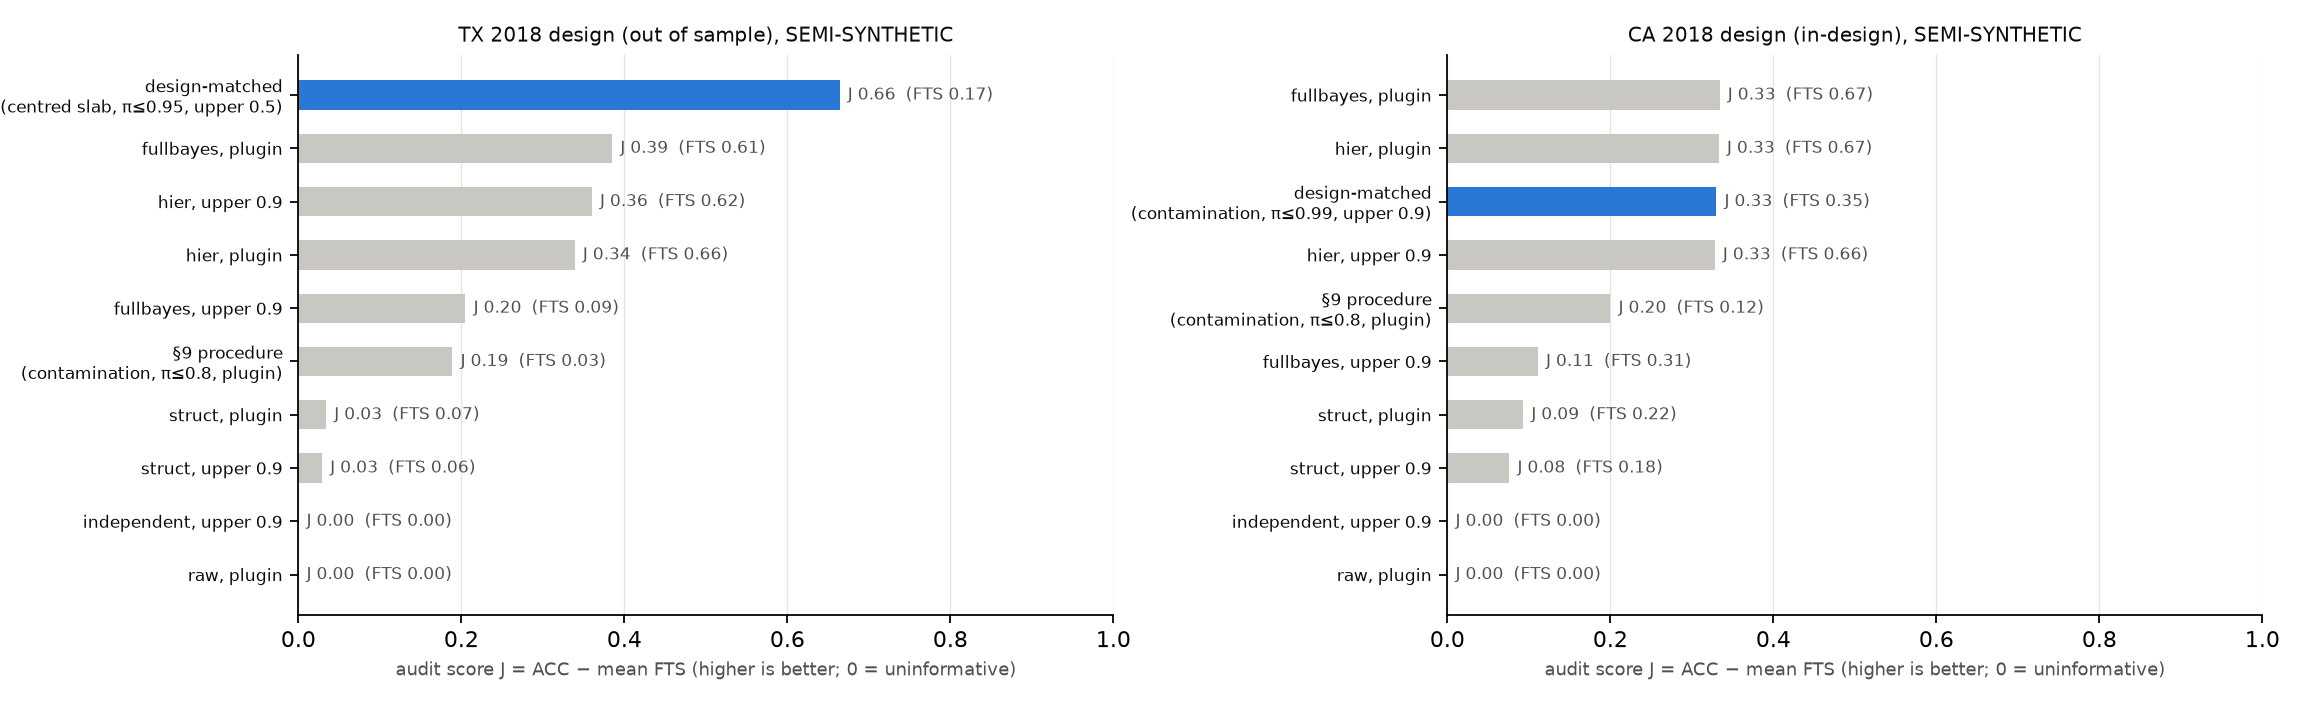

In [31]:
# Figure: audit score J by procedure (reads the scores saved by the previous cell, so it can be re-run on its own)
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
def pretty(p):
    p = re.sub(r"robustc@([0-9.]+)", r"centred slab, π≤\1", p); p = re.sub(r"robust@([0-9.]+)", r"contamination, π≤\1", p)
    p = p.replace("DESIGN-MATCHED", "design-matched").replace("upper0.", "upper 0.").replace(" · ", ", ")
    return p.replace(" (", "\n(", 1) if len(p) > 30 else p                                  # two lines for long labels
SC = {st_: pd.read_csv(f"results/v2_scores_{st_}.csv", index_col=0) for st_ in ("TX", "CA") if __import__("os").path.exists(f"results/v2_scores_{st_}.csv")}
fig, axs = plt.subplots(1, len(SC), figsize=(7.2 * len(SC), 4.4)); axs = np.atleast_1d(axs)
for ax, (st_, T) in zip(axs, SC.items()):
    T = T.sort_values("J"); cols = ["#2a78d6" if p_.startswith("DESIGN") else "#c8c7c1" for p_ in T.index]
    ax.barh(range(len(T)), T.J.clip(lower=0), height=.55, color=cols)
    for i, (v, f_) in enumerate(zip(T.J, T.meanFTS)):
        ax.text(max(v, 0) + .01, i, f"J {v:.2f}  (FTS {f_:.2f})", va="center", fontsize=7.5, color="#52514e")
    ax.set_yticks(range(len(T))); ax.set_yticklabels([pretty(p_) for p_ in T.index], fontsize=7.5, color="#0b0b0b"); ax.set_xlim(0, 1)
    ax.set_title(f"{st_} 2018 design ({'out of sample' if st_ == 'TX' else 'in-design'}), SEMI-SYNTHETIC", fontsize=9, color="#0b0b0b")
    ax.set_xlabel("audit score J = ACC − mean FTS (higher is better; 0 = uninformative)", fontsize=8, color="#52514e")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.grid(axis="x", color="#e6e5e0", lw=.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figures/v2_audit_score.png", dpi=160); plt.show()

In [32]:
# 15.4 Real data: the design-matched procedure as the validation-time selection criterion (5 household splits per state)
def select_with(sv, yv, gv, rng, est, kw, rule, eps=EPS):
    per = []
    for lam in LAMS:
        thr, tg = thresholds(sv, yv, gv, lam); d = apply_thr(sv, gv, thr, tg); T_ = group_table(yv, d, gv)
        a = audit(T_.k.values, T_.n_pos.values, est, eps=eps, qs=(.5, .75, .9), S=3000, rng=rng, labels=T_.index.values, **kw)
        per.append(dict(lam=lam, thr=thr, tg=tg, recall=d[yv == 1].mean(), crit=rule_val(a, rule)))
    ok = [r for r in per if r["crit"] <= eps]
    return (max(ok, key=lambda r: r["recall"]) if ok else min(per, key=lambda r: r["crit"])), bool(ok)

real_rows = []
for st_, dd_ in [("CA", df)] + ([("TX", TX_DF)] if TX_DF is not None else []):
    cal = CAL_DM[st_]
    for s in SEEDS:
        tr, va, te = household_split(dd_, s); sv, st = fit_all(tr, va, te, s, which=("BN",))["BN"]
        hh = np.array(va.SERIALNO.unique(), dtype=object); np.random.default_rng(500 + s).shuffle(hh)
        inA = va.SERIALNO.isin(set(hh[: len(hh) // 2])).values                                  # household-disjoint halves
        for mode in ("same-data", "held-out"):
            sel = inA if mode == "held-out" else np.ones(len(va), bool)
            r, claim = select_with(sv[sel], va.Y.values[sel], va.G.values[sel], np.random.default_rng(s), cal["est"], cal["kw"], cal["rule"])
            if mode == "held-out":                                                               # certify on the other half
                dB = apply_thr(sv[~inA], va.G.values[~inA], r["thr"], r["tg"]); TB = group_table(va.Y.values[~inA], dB, va.G.values[~inA])
                aB = audit(TB.k.values, TB.n_pos.values, cal["est"], qs=(.5, .75, .9), S=3000, rng=np.random.default_rng(s), labels=TB.index.values, **cal["kw"])
                claim = bool(rule_val(aB, cal["rule"]) <= EPS)
            d = apply_thr(st, te.G.values, r["thr"], r["tg"]); fm = fairness_metrics(te.Y.values, d, te.G.values)
            real_rows.append(dict(state=st_, seed=s, certification=mode, lam=round(float(r["lam"]), 2), val_claim=claim,
                                  test_dEOpp=fm["dEOpp"], test_recall=d[te.Y.values == 1].mean()))
REAL_V2 = pd.DataFrame(real_rows); REAL_V2.to_csv("results/v2_real_selection.csv", index=False)
print(REAL_V2.round(3).to_string(index=False))
for (st_, mode), g_ in REAL_V2.groupby(["state", "certification"]):
    print(f"{st_}, {mode} certification: {int(g_.val_claim.sum())} tolerance claims in {len(g_)} splits; "
          f"{int((g_.val_claim & (g_.test_dEOpp > EPS)).sum())} failed on test; mean test ΔEOpp {g_.test_dEOpp.mean():.3f}, recall {g_.test_recall.mean():.3f}")
HO = REAL_V2[REAL_V2.certification == "held-out"]
H2C = "SUPPORTED" if not (HO.val_claim & (HO.test_dEOpp > EPS)).any() else "NOT SUPPORTED"
print(f"H2c (held-out certification: no tolerance claim fails on test): {H2C}  [{int(HO.val_claim.sum())} held-out claims made]")

state  seed certification  lam  val_claim  test_dEOpp  test_recall
   CA     0     same-data  1.0       True       0.357        0.374
   CA     0      held-out  1.0      False       0.383        0.375
   CA     1     same-data  1.0       True       0.341        0.382
   CA     1      held-out  0.9      False       0.349        0.379
   CA     2     same-data  1.0       True       0.338        0.377
   CA     2      held-out  0.9      False       0.308        0.377
   CA     3     same-data  1.0       True       0.326        0.384
   CA     3      held-out  0.9      False       0.410        0.380
   CA     4     same-data  1.0       True       0.472        0.384
   CA     4      held-out  1.0      False       0.306        0.385
   TX     0     same-data  1.0       True       0.285        0.360
   TX     0      held-out  1.0      False       0.315        0.359
   TX     1     same-data  0.9       True       0.216        0.350
   TX     1      held-out  0.9      False       0.242        0

**Findings, §15 (semi-synthetic results describe the procedures, not the populations).**
1. **Diagnosis.** In fair worlds on the CA design, 90.1% of the §9 procedure's false alarms come from a max- or min-group with
   fewer than 10 positives, and in only 1.5% are both extreme groups well supported (≥ 30 positives).
2. **Design-matched choices.** For CA the calibration chose a fixed slab with π ≤ 0.99 and the upper-0.9 rule; for TX, a
   centred slab with π ≤ 0.95 and the upper-0.5 rule. In both designs it chose an **upper-quantile** rule, unlike §9's
   plug-in choice. The centred slab helped on the TX calibration worlds (best J 0.295 vs 0.250) but not on CA (0.430 vs
   0.445), so its value depends on the design.
3. **Texas, out of sample: H2a and H2b SUPPORTED.** The design-matched procedure scores **J = 0.664**, against 0.385 for the
   best established audit (full Bayes plug-in) and 0.189 for the §9 procedure. Its mean FTS is **0.168** (cell 0.255,
   interaction 0.250, disability main effect 0), against 0.615–0.661 for full-Bayes and hierarchical pooling. Its ACC is
   0.832, and its 90% gap intervals cover 0.615, the highest of all procedures (the others are at most 0.506).
4. **California, in-design (used for the pilot, so not a test).** Here J = 0.330 only **ties** hier plug-in (0.333) and full
   Bayes plug-in (0.334), but with about half their false-certification rate (mean FTS 0.348 vs 0.666–0.667) at a lower
   ACC (0.678 vs 1.000). The calibration-world J (0.445) did not fully carry over to the harder evaluation worlds
   (deficit at a 24-positive group, interaction structure, thinning). On CA the gain is in safety, not in J.
5. **Held-out certification: H2c SUPPORTED.** Certifying on the same validation data claimed "ε satisfied" in 5 of 5 splits
   in both states, and every claim was false on test (mean test ΔEOpp 0.367 CA, 0.238 TX). Certifying on held-out
   validation households made **no false claims**, at unchanged recall (0.379 vs 0.380 CA; 0.350 vs 0.350 TX).
   *Limitation:* no rule in this family is truly fair, so this shows that held-out certification avoids false
   certificates. It cannot show that it would correctly certify a truly fair rule; the semi-synthetic ACC in item 3 speaks
   to that.

## 16. Requirement-by-requirement verification

In [33]:
checklist = [
 ("Dataset: ACSPublicCoverage via Folktables, CA 2018", "§1", "Folktables get_data/df_to_numpy; identical features, exact label reversal"),
 ("Target reversal, Y=1 no public coverage; not uninsured/eligible", "§1 data card", "done"),
 ("Protected: race, sex, disability; race×sex×disability + two-attribute baseline", "§5", "done (3 single, 3 two-way, 1 three-way)"),
 ("Compact predictive BN, smoothed, variable elimination", "§3", "done; Dirichlet α=1"),
 ("Hierarchical audit: beta-binomial, EB and small hierarchical sampler", "§6", "EB + full-Bayes grid posterior + attribute-structured logistic (struct) + proposed contamination prior"),
 ("Fairness metrics: intersectional EOpp gaps, worst-group recall, posterior intervals, P(Δ>ε|data)", "§4, §7, §10", "done"),
 ("Shared metrics: ΔDP, ΔEOpp, ΔEOdds, R_sel, denominators, <30 flags", "§4, §5", "done"),
 ("Predictive baselines LR, GBT", "§4.1", "done, with fairness and calibration"),
 ("GM baseline: BN with Dirichlet tables, no uncertainty-aware selection", "§10 raw_plugin / hier_plugin", "done"),
 ("Fairness baselines: raw, independent beta-binomial, established hierarchical, EOpp threshold adjustment", "§6, §10 (λ=1)", "done; established hierarchical = struct (§6, §6.1)"),
 ("Task 1: attribute-structured hierarchical audit (struct)", "§6, §6.1, §7, §9.2, §10, §12, §14",
  "done: marginal-likelihood fit by adaptive quadrature (checked vs brute force and finite differences); coverage reported vs oracle; "
  "in §7 table/figure, §10 CRITERIA struct_plugin/struct_upper, §12. Restricted version in the spirit of [24], NOT an exact reproduction"),
 ("Task 2: semi-synthetic simulation on the real validation design", "§9.2",
  f"done: R={R_SEMI}, homogeneous + cell / interaction-only / disability-main-effect deficits at 2|2|1, thinning 1/0.5/0.25; "
  "FTS, ACC, coverage, width, ex_worst; calibrated procedure frozen from §9 (not re-chosen)"),
 ("Exp1 single vs intersectional", "§5", "done"),
 ("Exp2 thin train/val intersections, independent evaluation", "§10", "done; 4 thinning levels × 5 seeds"),
 ("Exp3 empirical vs independent vs pooled", "§7", "done"),
 ("Exp4 homogeneous vs exceptional simulation: coverage, false fairness conclusions", "§8 (synthetic), §9.2 (semi-synthetic)", "done"),
 ("Exp5 ordinary vs uncertainty-aware selection at matched capacity/utility", "§10", "done; capacity matched exactly on validation (test 0.292–0.305)"),
 ("Ablation: no pooling / complete pooling / posterior mean instead of upper quantile", "§8, §10", "done"),
 ("Robustness: priors & pooling strength, prevalence, tolerances, thinning rates, atypical small group, 2nd state", "§9.1, §12, §10, §14", "done; TX 2018 replication run in §14"),
 ("Probabilistic metrics: log loss, Brier, group calibration, PPC, interval width", "§4.1, §7, §8", "done"),
 ("Household dependence; declared survey estimand", "§2, §11, §13", "done"),
 ("Frequentist coverage of Bayesian intervals by repeated simulation", "§6.1, §8, §9.2", "done"),
 ("Visualise hierarchical structure; quantify pull; compare with raw held-out counts", "§6, §7", "done"),
 ("Calibrate tolerance procedure by simulation", "§9", "done, preregistered Youden rule"),
 ("Protocol 5/6/9: ≥5 seeds, ≥1000 cluster bootstrap, Holm, effect sizes", "§10, §11", "done"),
 ("Protocol 10: VE vs clique tree agreement, normalisation, joint CI", "§3.1", "done, tolerance 1e-9"),
 ("Protocol 11: synthetic results labelled", "§6.1, §8, §9, §9.2", "done (SYNTHETIC / SEMI-SYNTHETIC labels)"),
 ("Literature review ≥8 papers (incl. recent), comparison table, closest method", "top cell; writeup/literature_review.pdf", "done: 19 verified papers, 2016–2025; closest = Foulds et al. 2020, Herlihy et al. 2024"),
 ("Narrow the claim where the literature already answers it", "top cell", "done: contamination prior, Bayesian fairness uncertainty, marginal-vs-intersectional and fairness generalization are prior work; claim narrowed to the evaluation"),
 ("Falsifiable contribution in one sentence", "top cell, §14.1", "done: H1, formed on CA and tested out of sample on TX 2018 -> " + (H1_VERDICT if "H1_VERDICT" in globals() else "not run (REPLICATION_STATES empty)")),
 ("Improvement: diagnosis, design-matched calibration, held-out certification (H2a-c)", "§15",
  "done: preregistered, tested out of sample on TX -> H2a " + globals().get("H2A", "not run") + ", H2b " + globals().get("H2B", "not run") + ", H2c " + globals().get("H2C", "not run")),
 ("Model card, assumptions register, manuscript", "writeup/", "drafted in LaTeX; TODO fields (names, licence, stakeholder input) left for the students"),
 ("Individual contribution statements, demonstration, oral defence", "—", "students only (cannot be written by anyone else)"),
]
print(pd.DataFrame(checklist, columns=["requirement", "where", "status"]).to_string(index=False))
print(f"\nTotal runtime: {(time.time()-T0)/60:.1f} min")

                                                                                                   requirement                                   where                                                                                                                                                                                                                                                                   status
                                                            Dataset: ACSPublicCoverage via Folktables, CA 2018                                      §1                                                                                                                                                                                                Folktables get_data/df_to_numpy; identical features, exact label reversal
                                               Target reversal, Y=1 no public coverage; not uninsured/eligible                            §1 data card                  

## 17. Conclusions (from this run; seeds fixed)

**Primary question: when does hierarchical pooling help, and when does it mask a harmful small-group disparity?**
- *It masks a disparity* when a deficit is confined to a small intersection and the remaining groups are tight. On the
  synthetic design (§8) and on the real CA intersection design with invented TPRs (§9.2), exchangeable EB pooling declares
  ΔEOpp ≤ 0.10 in 98–100% of worlds where Black, female, disabled adults (24 positives) have a TPR 0.20 lower. An
  upper posterior quantile does not fix this, because shrinkage moves the group's posterior location to ≈ 0.38. The
  attribute-structured baseline (`struct`) masks the same deficit when it is an interaction, i.e. when the group's main
  effects look like everyone else's.
- *It does not mask a disparity* that is carried by a main effect spread over many or large groups (the disability world
  in §9.2: FTS = 0 for every estimator). The same holds on real CA 2018 data (§7): the BN rule's disparity is structural
  (every DIS = 1 intersection has TPR ≤ 0.08) and spread across large groups, so pooling moves no group with ≥ 30
  positives by more than 0.032. All audits give P(ΔEOpp > 0.10) = 1.0. Texas 2018 replicates this (§14).
- *On real data, pooling misleads at selection time.* When λ is chosen on validation, the pooled criteria (hier,
  fullbayes, complete, the calibrated proposed rule, and struct in 2 of 5 splits) report ε = 0.10 as satisfied. **All 116
  such validation-time claims are false on the independent test split** (test ΔEOpp 0.23–0.77). The raw and independent
  criteria never make such a claim.
- **Falsifiable contribution H1 (stated at the top, tested out of sample on Texas 2018 in §14.1): supported.** 27 of 27
  pooled validation-time tolerance claims failed on the Texas test split (test ΔEOpp 0.110–0.888).

**Secondary questions.** *Pooling strength and group size vs coverage:* exchangeable pooling gives near-zero gap-interval
coverage (hier 0.000, fullbayes 0.038 in §8). The EB attribute-structured audit under-covers even under its own model
(0.665 vs nominal 0.90; 0.53 for groups with < 30 positives, §6.1), while the oracle check gives 0.905. *Can posterior
uncertainty improve threshold selection?* Only once calibration matches the design. On the invented design the Youden
rule chose a plug-in rule (§9). Under design-matched calibration it chose upper-quantile rules in both states (§15), and
that procedure is the best audit on the out-of-sample Texas design. *Stability across samples:* the confirmatory comparisons are not significant under
evaluation uncertainty (Holm p = 1.0 and 0.736, §11), and the paired differences change sign across the 5 refits
(training uncertainty). The earlier seed-0 result (Holm p = 0.04) does not reproduce.

**What the proposed method achieves (positive contribution, §15).** The diagnosis (90% of false alarms come from groups
with < 10 positives) explains why a calibration made on one design fails on another (ACC 0.83 → 0.32, §9.2). The fix has
two parts. **(i) Design-matched calibration**, on the deployment population's own validation group sizes, chooses the
prior strength and decision rule. On the out-of-sample Texas design it raises the audit score J from 0.189 to **0.664**,
against at most 0.385 for every established audit, and cuts false certification to **0.168**, against 0.615–0.661 for
hierarchical and full-Bayes pooling (H2a, H2b supported). **(ii) Held-out certification** (choose λ on half of the
validation households, certify on the other half) removes the validation-time false certificates. Same-data certification
claimed fairness in 10 of 10 CA/TX splits, all false on test; held-out certification made none, at unchanged recall (H2c
supported). **Limits:** on the California design the gain is in safety (half the false-certification rate) rather than J,
which ties the pooled audits. No configuration reaches FTS < 0.10 with ACC > 0.5 on the invented design, an information
limit at ≈ 10–20 positives per group. The original §9 procedure did not reduce the real test gap (§11). The
semi-synthetic worlds share one generator family.

**Responsible interpretation.** No audit here shows that the outreach rule is fair. Every rule in the family leaves a
test ΔEOpp of at least 0.23, at a mean recall cost of 0.008 (at most 0.013 in any split; budget 0.02). Y = 1 means *no public coverage*: it is not uninsurance and not
program eligibility, and D = 1 is hypothetical outreach. Simulated and semi-synthetic TPRs are not facts about the
population. `struct` is a documented restricted version of a hierarchical intersectional audit in the spirit of [24];
exact reproduction is pending the literature step. Auditors should report raw counts, the pooling pull (§7) and
P(Δ > ε) together. They should never certify a tolerance from a pooled estimate when some intersection has fewer than
~30 positives, they should calibrate any tolerance procedure on the design it will be used on, and certify on data not used to choose the rule.

**Done outside this notebook:** literature review of 19 verified papers with a comparison table (`docs/related_work.md`,
`writeup/literature_review.pdf`), the narrowed claim, manuscript, model card, assumptions register, contribution statements
(Sumedh Navuda and Aldino), the 3-page report (`report/`), the slides (`slides/`), the requirement matrix
(`docs/requirements_matrix.md`) and the demonstration (`demo/`). Paired 95% intervals for ΔJ are computed from the saved
§15 outputs by `writeup/make_tables.py` (TX: +0.279 [0.235, 0.322]). Not attempted: an exact reproduction of [24].